# Zaawansowana analityka biznesowa – metody imputacji danych
## Zadanie nr 1, wersja A (zmienna ciągła)

**Zbiór danych:** `ka01.csv` ($N = 805$ obserwacji, $5$ zmiennych źródłowych: `y_t1`, `x1`, `trt`, `x2`, `y_t2`)  
**Autorzy:** Iwo Ceglarek, Maciek Staniec, Miłosz Granat, Piotr Szuta 121583, Szymon Józefczyk

---

### Spis treści
1. **Punkt 1.** Analiza struktury danych oraz zakresu i rozkładu braków *(gotowe)*
2. **Punkt 2.** Ocena zależności występowania braków danych od pozostałych cech *(gotowe)*
3. **Punkt 3.** Model ANCOVA (MCAR / MAR / MNAR 1D i 2D *tipping-point*) *(gotowe)*
4. **Punkt 4.** Podsumowanie wyników estymacji w kontekście braków danych *(gotowe)*
5. **Punkt 5.** *[Miejsce na rozwiązanie Punktu 5 oraz wnioski końcowe – do uzupełnienia przez zespół]*

---

In [1]:
# Wspólna konfiguracja ścieżek i parametrów dla całego raportu (Punkty 1–5)
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
CSV_FILE = DATA / "ka01.csv"
FIG = ROOT / "figures"
RES = ROOT / "results"
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import punkt3_ancova_mi as p3

SEED = p3.SEED    # 42
M_IMP = p3.M_IMP  # 100
ALPHA = p3.ALPHA  # 0.05
DPI = 300

sns.set_theme(style="whitegrid", context="notebook")
print(f"Zbiór danych: {CSV_FILE.name} | SEED = {SEED} | m = {M_IMP} | alpha = {ALPHA}")

Zbiór danych: ka01.csv | SEED = 42 | m = 100 | alpha = 0.05


# Punkt 1. Analiza struktury danych i ocena braków

**Cel badania:** ocena średniej zmiany `CHG = Y_T2 − Y_T1` w grupie z czynnikiem (`TRT=1`) i kontrolnej (`TRT=2`) oraz różnicy między grupami, modelem analizy kowariancji.

**Zakres punktu 1:**
1. analiza struktury z podziałem na cechy **ciągłe** i **skokowe**,
2. **graficzna** ocena wyników badania,
3. ocena **zakresu** i **rozkładu** braków danych.

## 1. Wczytanie danych i definicja ról zmiennych

Role zmiennych zgodnie z projektem badania:

| Zmienna | Typ | Rola |
|---|---|---|
| `y_t1` | ciągła | pomiar w t_1 |
| `y_t2` | ciągła | pomiar w t_2 |
| `x1` | ciągła | cecha stanu początkowego |
| `trt` | skokowa |1 = grupa z czynnikiem, 2 = grupa kontrolna |
| `x2` | skokowa | cecha skokowa stanu początkowego (0/1) |
| `chg` = `y_t2 − y_t1` | ciągła  | zmienna zależna modelu |

Zmienna `chg` powstaje z `y_t2`, więc brak w `y_t2` automatycznie oznacza brak w `chg`. Problem braków dotyczy zatem zmiennej objaśnianej modelu, a więc nie można go pominąć.

In [2]:
df = pd.read_csv(CSV_FILE)
df["chg"]     = df["y_t2"] - df["y_t1"]
df["trt_lab"] = df["trt"].map({1: "TRT=1 (czynnik)", 2: "TRT=2 (kontrola)"})

CIAGLE  = ["y_t1", "x1", "y_t2", "chg"]
SKOKOWE = ["trt", "x2"]
PAL = {"TRT=1 (czynnik)": "#2a6f97", "TRT=2 (kontrola)": "#c1121f"}

print("Wymiary zbioru:", df.shape)
df.head()

Wymiary zbioru: (805, 7)


,y_t1,x1,trt,x2,y_t2,chg,trt_lab
0,9.632983,55.158388,1,0,7.764858,-1.868124,TRT=1 (czynnik)
1,11.885582,49.207020,1,1,10.669919,-1.215663,TRT=1 (czynnik)
2,10.449324,47.741301,1,1,11.215358,0.766034,TRT=1 (czynnik)
3,9.399263,39.062814,1,0,NaN,NaN,TRT=1 (czynnik)
4,11.186338,49.632284,1,0,9.510397,-1.675941,TRT=1 (czynnik)


## 2. Struktura cech ciągłych

Dla każdej cechy ciągłej liczymy zestaw statystyk oraz miary kształtu rozkładu:
- skośność
- kurtoza

Statystyki `y_t2` i `chg` liczone są tylko na obserwacjach kompletnych.

In [3]:
def opis_ciaglej(s: pd.Series) -> pd.Series:
    # Zestaw statystyk opisowych dla jednej cechy ciągłej (pomija braki)
    s = s.dropna()
    return pd.Series({
        "n": int(s.size),
        "śr": s.mean(), "sd": s.std(ddof=1),
        "min": s.min(), "Q1": s.quantile(.25), "med": s.median(),
        "Q3": s.quantile(.75), "max": s.max(),
        "skośność": stats.skew(s),
        "kurtoza": stats.kurtosis(s),
    })

struktura = df[CIAGLE].apply(opis_ciaglej).T
struktura["braki"] = df[CIAGLE].isna().sum().values
struktura.round(3)

,n,śr,sd,min,Q1,med,Q3,max,skośność,kurtoza,braki
y_t1,805.0,10.886,0.990,7.562,10.231,10.877,11.557,14.772,0.058,0.115,0
x1,805.0,52.435,6.122,32.515,48.467,52.100,56.369,72.258,0.194,0.155,0
y_t2,544.0,10.197,2.483,0.583,8.691,10.359,11.757,17.760,-0.294,0.707,261
chg,544.0,-0.626,2.433,-10.350,-2.066,-0.487,0.967,6.932,-0.385,0.618,261


Wszystkie cechy mają rozkłady bliskie symetrycznym i bez grubych ogonów, zatem brak podstaw do transformacji. `y_t1` i `x1` są kompletne, zaś `y_t2` (i `chg`) mają po 261 braków. Rozstęp `y_t2` jest szeroki, a co za tym, warto zauważyć pojedyncze niskie wartości.

### 2a. Cechy ciągłe w podziale na grupy TRT

In [4]:
for v in ["y_t1", "x1", "y_t2", "chg"]:
    print(f"-- {v} wg grup --")
    display(df.groupby("trt_lab")[v].apply(opis_ciaglej).unstack().round(3))

-- y_t1 wg grup --


,n,śr,sd,min,Q1,med,Q3,max,skośność,kurtoza
trt_lab,,,,,,,,,,
TRT=1 (czynnik),380.0,10.86,0.961,7.562,10.254,10.871,11.540,13.314,-0.110,0.025
TRT=2 (kontrola),425.0,10.91,1.016,8.362,10.213,10.907,11.576,14.772,0.178,0.138


-- x1 wg grup --


,n,śr,sd,min,Q1,med,Q3,max,skośność,kurtoza
trt_lab,,,,,,,,,,
TRT=1 (czynnik),380.0,49.552,5.302,32.515,46.270,49.445,53.084,64.987,-0.006,0.177
TRT=2 (kontrola),425.0,55.013,5.642,39.876,50.682,54.524,58.472,72.258,0.340,-0.142


-- y_t2 wg grup --


,n,śr,sd,min,Q1,med,Q3,max,skośność,kurtoza
trt_lab,,,,,,,,,,
TRT=1 (czynnik),242.0,11.294,2.076,6.153,9.857,11.433,12.687,17.760,0.025,0.125
TRT=2 (kontrola),302.0,9.318,2.435,0.583,7.961,9.587,10.722,16.584,-0.306,0.911


-- chg wg grup --


,n,śr,sd,min,Q1,med,Q3,max,skośność,kurtoza
trt_lab,,,,,,,,,,
TRT=1 (czynnik),242.0,0.453,2.050,-5.074,-0.962,0.687,1.798,6.932,-0.068,0.126
TRT=2 (kontrola),302.0,-1.490,2.372,-10.350,-2.807,-1.192,0.034,4.338,-0.463,0.628


Zmienna `y_t1` jest niemal identyczna w obu grupach, natomiast średnia `chg` wynosi 0,45 przy czynniku i −1,49 w grupie kontrolnej (różnica wynosi około 1,94). To pewien sygnał efektu zmiennej `TRT`, ale należy podchodzić do niego ostrożnie, gdyż liczony jest na obserwacjach niepustych i może być obciążony. Warto zwrócić też uwagę na wyższe `x1` w grupie kontrolnej. Grupy nie są idealnie zbalansowane, co uzasadnia model z kowariantą zamiast prostej różnicy średnich.

## 3. Struktura cech skokowych

Dla cech skokowych podajemy liczności i udziały oraz tabelę krzyżową `trt × x2`.

In [5]:
for v in SKOKOWE:
    t = df[v].value_counts().sort_index()
    print(f"\n{v}:")
    display(pd.DataFrame({"n": t, "%": (t / len(df) * 100).round(2)}))

print("\nTabela krzyżowa trt × x2:")
pd.crosstab(df["trt"], df["x2"], margins=True)


trt:


,n,%
trt,,
1,380,47.2
2,425,52.8



x2:


,n,%
x2,,
0,418,51.93
1,387,48.07



Tabela krzyżowa trt × x2:


x2,0,1,All
trt,,,
1,128,252,380
2,290,135,425
All,418,387,805


Grupy `trt` są zbliżone liczebnie. Zmienna `x2` jest powiązana z `trt` (w grupie czynnika przeważa `x2=1`, w kontrolnej `x2=0`). To sygnał, że `x2` niesie informację o jednostkach i może być użyteczne przy korekcie braków.

## 4. Zakres i rozkład braków danych

Oceniamy:
- zakres - ile braków łącznie i dla zmiennych,
- wzorzec - które komórki brakują,
- rozkład - jak braki rozkładają się względem grup i cech

In [6]:
kol = ["y_t1", "x1", "trt", "x2", "y_t2"]

print("Braki per zmienna:")
miss = df[kol].isna().sum()
display(pd.DataFrame({"n_braków": miss, "%": (miss / len(df) * 100).round(2)}))

print("Braki per obserwacja (liczba brakujących komórek w wierszu):")
display(df[kol].isna().sum(axis=1).value_counts().sort_index())

Braki per zmienna:


,n_braków,%
y_t1,0,0.00
x1,0,0.00
trt,0,0.00
x2,0,0.00
y_t2,261,32.42


Braki per obserwacja (liczba brakujących komórek w wierszu):


0    544
1    261
Name: count, dtype: int64

Braki występują wyłącznie w `y_t2`: 261 z 805 obserwacji = 32,4%. To duży odsetek, zatem analiza wyłącznie na przypadkach kompletnych oznaczałaby utratę  około 1/3 próby. Ponieważ brakuje tylko jednej zmiennej, wzorzec jest jednowymiarowy. W macierzy niezerowa jest jedynie kolumna `y_t2`, a każdy niekompletny wiersz ma dokładnie jeden brak.

### 4a. Wzorzec i kompletność - wizualizacja

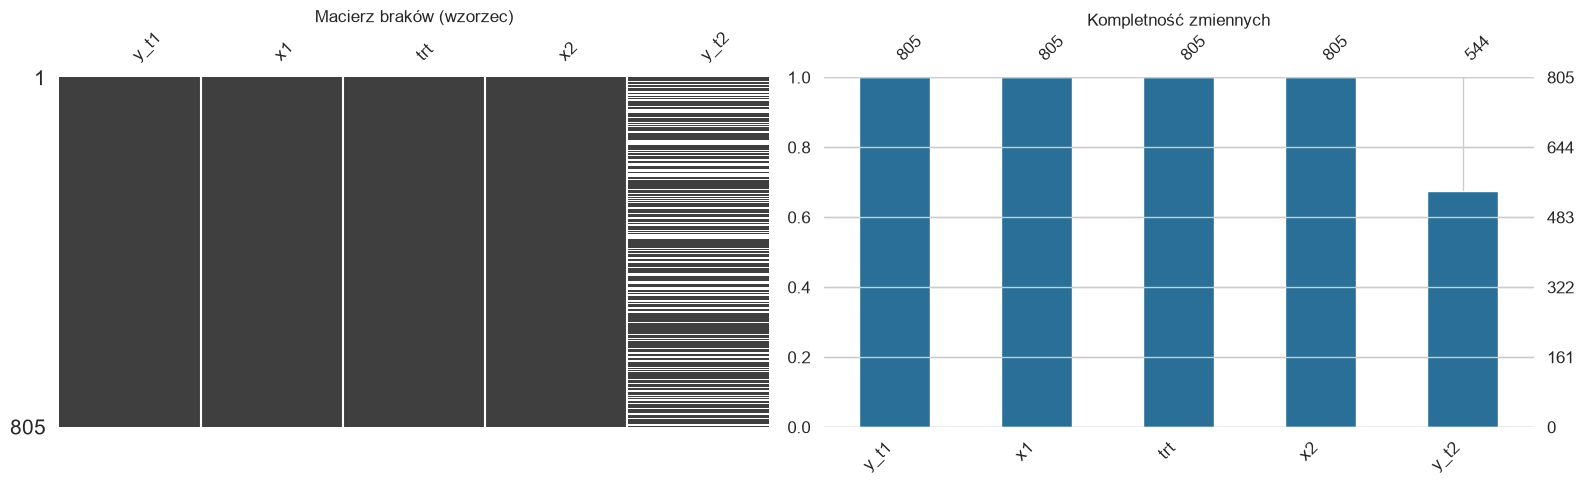

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
msno.matrix(df[kol], ax=ax[0], sparkline=False, fontsize=12)
ax[0].set_title("Macierz braków (wzorzec)")
msno.bar(df[kol], ax=ax[1], fontsize=12, color="#2a6f97")
ax[1].set_title("Kompletność zmiennych")
plt.tight_layout()
plt.savefig(FIG / "fig1_braki_wzorzec.png", dpi=DPI, bbox_inches="tight")
plt.show()

### 4b. Rozkład braków `y_t2` względem grup

Rozkład braków y_t2 wg cech skokowych:


,n,braki,%_braków
trt_lab,,,
TRT=1 (czynnik),380.0,138.0,36.32
TRT=2 (kontrola),425.0,123.0,28.94


,n,braki,%_braków
x2,,,
0,418.0,132.0,31.58
1,387.0,129.0,33.33


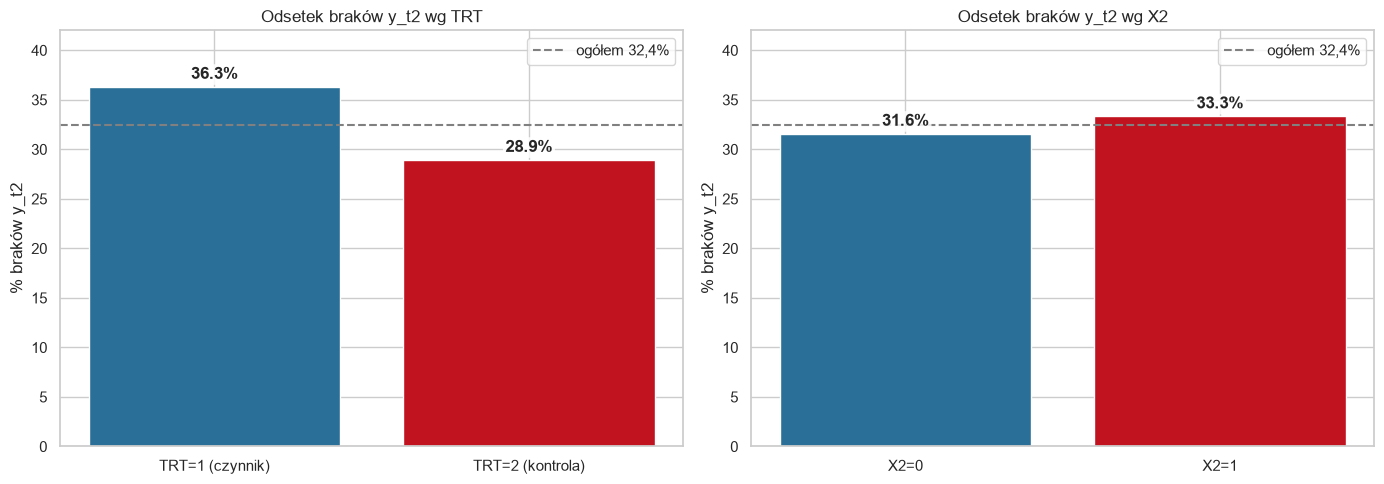

In [8]:
print("Rozkład braków y_t2 wg cech skokowych:")
for v in ["trt_lab", "x2"]:
    g = df.groupby(v)["y_t2"].apply(lambda s: pd.Series(
        {"n": s.size, "braki": s.isna().sum(), "%_braków": round(s.isna().mean() * 100, 2)}))
    display(g.unstack())

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (var, lab) in zip(ax, [("trt_lab", "TRT"), ("x2", "X2")]):
    m = df.groupby(var)["y_t2"].apply(lambda s: s.isna().mean() * 100)
    x_labels = [f"X2={k}" for k in m.index] if var == "x2" else m.index.astype(str)
    a.bar(x_labels, m.values, color=["#2a6f97", "#c1121f"])
    a.axhline(df["y_t2"].isna().mean() * 100, ls="--", c="gray", label="ogółem 32,4%")
    a.set_ylim(0, 42)
    a.set_ylabel("% braków y_t2"); a.set_title(f"Odsetek braków y_t2 wg {lab}")
    a.legend(loc="upper right")
    for i, val in enumerate(m.values):
        a.text(i, val + 0.8, f"{val:.1f}%", ha="center", fontweight="bold",
               bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
plt.tight_layout()
plt.savefig(FIG / "fig2_braki_grupy.png", dpi=DPI, bbox_inches="tight")
plt.show()

Odsetek braków `y_t2` wynosi 36,3% w grupie czynnika i 28,9% w kontrolnej, podczas gdy względem `x2` jest jednak bardziej zbliżony. Różnica względem `trt` sugeruje, że mechanizm braków prawdopodobnie nie jest MCAR. Brak zależy przynajmniej od przynależności do grupy. Na podstawie samej próby niestety nie rozstrzygniemy, czy to MAR czy MNAR.

## 5. Graficzna ocena wyników badania

### 5a. Rozkłady cech ciągłych wg grup

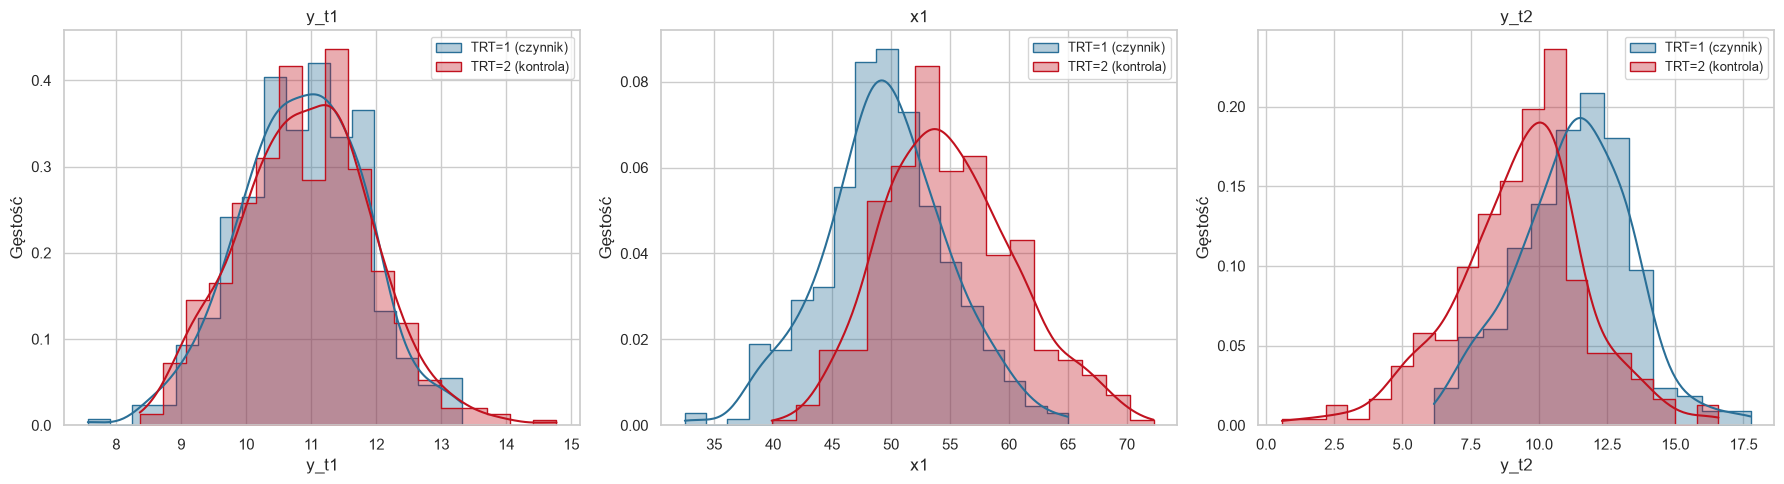

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, v in zip(ax, ["y_t1", "x1", "y_t2"]):
    for lab, g in df.groupby("trt_lab"):
        sns.histplot(g[v].dropna(), ax=a, kde=True, stat="density",
                     color=PAL[lab], alpha=.35, label=lab, element="step")
    a.set_title(v); a.set_ylabel("Gęstość"); a.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIG / "fig3_rozklady.png", dpi=DPI, bbox_inches="tight")
plt.show()

### 5b. Wykresy pudełkowe wg grup (widać efekt czynnika)

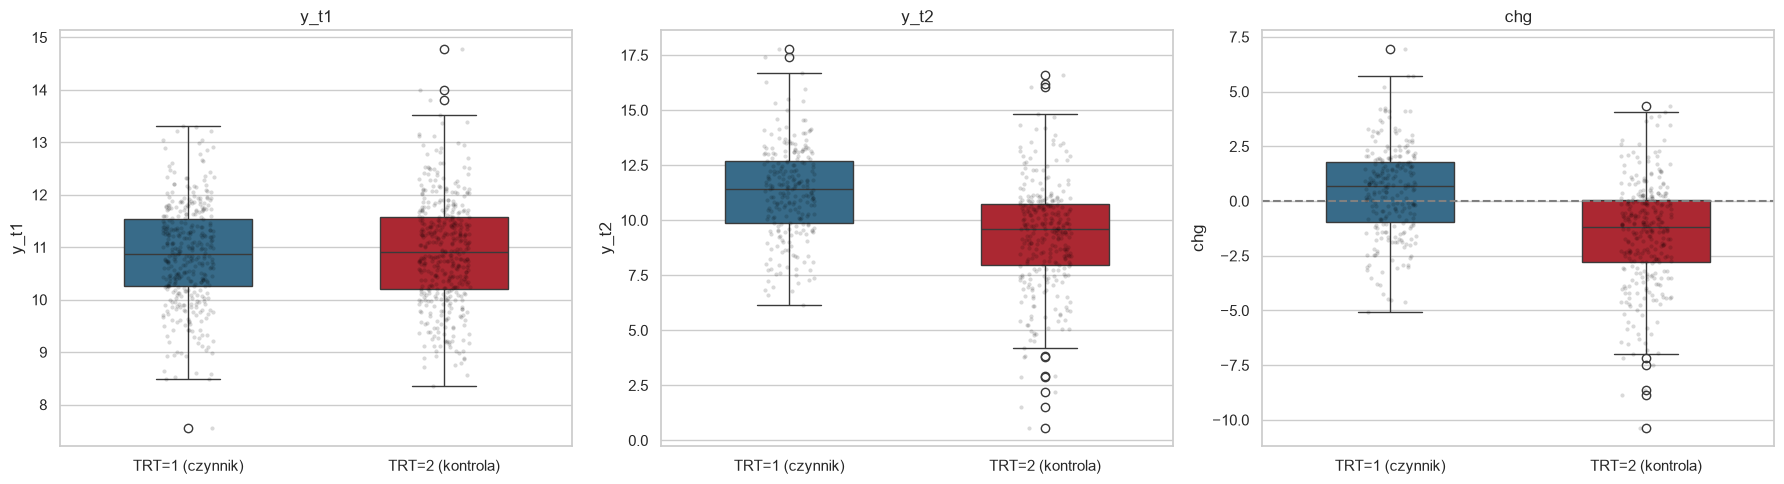

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, v in zip(ax, ["y_t1", "y_t2", "chg"]):
    sns.boxplot(data=df, x="trt_lab", y=v, hue="trt_lab", ax=a,
                palette=PAL, width=.5, legend=False)
    sns.stripplot(data=df, x="trt_lab", y=v, ax=a, color="black", alpha=.15, size=3)
    a.set_title(v); a.set_xlabel("")
    if v == "chg":
        a.axhline(0, ls="--", c="gray")   # linia braku zmiany
plt.tight_layout()
plt.savefig(FIG / "fig4_boxploty.png", dpi=DPI, bbox_inches="tight")
plt.show()

Zmienna `y_t1` pokrywa się między grupami, natomiast `y_t2` i `chg` są wyraźnie rozsunięte: mediana `chg` jest dodatnia dla grupy czynnika, lecz ujemna dla kontroli. Pojedyncze bardzo niskie `y_t2`/`chg` w kontroli to obserwacje odstające (outliers).

### 5c. Zależność `y_t2 ~ y_t1` wg grup

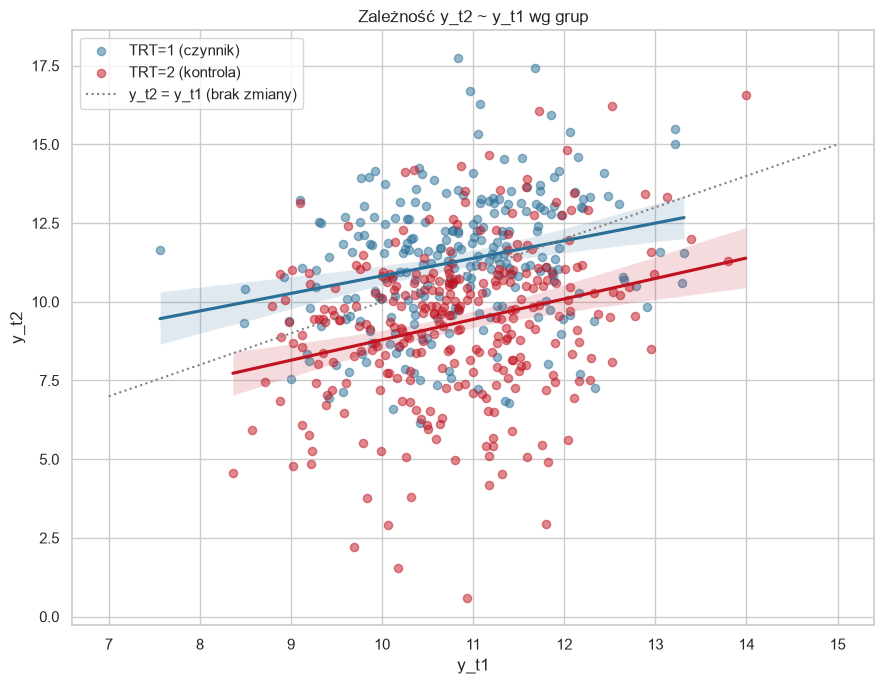

In [11]:
fig, ax = plt.subplots(figsize=(9, 7))
for lab, g in df.groupby("trt_lab"):
    sns.regplot(data=g, x="y_t1", y="y_t2", ax=ax, color=PAL[lab],
                label=lab, scatter_kws=dict(alpha=.5, s=35))
ax.plot([7, 15], [7, 15], ls=":", c="gray", label="y_t2 = y_t1 (brak zmiany)")
ax.set_title("Zależność y_t2 ~ y_t1 wg grup")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "fig5_scatter.png", dpi=DPI, bbox_inches="tight")
plt.show()

W obu grupach występuje dodatnia zależność `y_t2` od `y_t1`. Włączenie `y_t1` do modelu redukuje wariancję resztową. Chmura grupy czynnika leży wyżej, co jest graficznym odpowiednikiem dodatniego $\beta_1$.

---

# Punkt 2. Ocena zależności występowania braków danych od pozostałych cech

## Cel analizy

Celem analizy jest sprawdzenie, czy prawdopodobieństwo braku wartości zmiennej `y_t2` jest powiązane z wartościami pozostałych cech zbioru danych. Wyniki pozwolą wskazać zmienne, które mogą być pomocne przy imputacji brakujących wartości `y_t2`.

W analizie wykorzystano wskaźnik braków danych oraz dwie metody oceny zależności:
1. porównanie średnich wartości cech ciągłych w grupie obserwacji z brakującą i zaobserwowaną wartością `y_t2`;
2. ocenę zależności wskaźnika braków od cech skokowych za pomocą tabel kontyngencji i miar asocjacji.

Dodatkowo zastosowano regresję logistyczną, aby ocenić jednoczesny związek wszystkich pozostałych cech z występowaniem braku `y_t2`.

In [12]:
df = pd.read_csv(CSV_FILE)
print(f"Liczba obserwacji: {len(df)}")
print(f"Liczba zmiennych: {df.shape[1]}")

Liczba obserwacji: 805
Liczba zmiennych: 5


## 1. Przygotowanie wskaźnika braków danych

W zbiorze braki występują w zmiennej `y_t2`. Dla tej zmiennej utworzono wskaźnik `R_y_t2`, który przyjmuje wartość 1, gdy obserwacja jest brakująca, oraz 0, gdy wartość została zaobserwowana.

W dalszej analizie zmienną `R_y_t2` traktuje się jako zmienną zależną, a pozostałe cechy jako potencjalne zmienne wyjaśniające występowanie braków.

In [13]:
df["R_y_t2"] = df["y_t2"].isna().astype(int)

predictors = ["y_t1", "x1", "trt", "x2"]

if df[predictors].isna().any().any():
    raise ValueError("W zmiennych objaśniających występują braki danych.")

n_missing = int(df["R_y_t2"].sum())
n_observed = int((df["R_y_t2"] == 0).sum())

missing_summary = pd.DataFrame({
    "Liczba obserwacji": [n_observed, n_missing],
    "Udział (%)": [
        100 * n_observed / len(df),
        100 * n_missing / len(df)
    ]
}, index=["y_t2 zaobserwowane (R=0)", "y_t2 brakujące (R=1)"])

display(missing_summary.round(2))

,Liczba obserwacji,Udział (%)
y_t2 zaobserwowane (R=0),544,67.58
y_t2 brakujące (R=1),261,32.42


## 2. Porównanie średnich cech ciągłych

Pierwsza metoda polega na podziale obserwacji na dwie grupy: z brakującą i zaobserwowaną wartością `y_t2`. Następnie porównywane są średnie wartości cech ciągłych w tych grupach.

Dla każdej cechy zastosowano test t Welcha. Test ten pozwala porównać średnie bez przyjmowania założenia o równości wariancji w obu grupach.

Hipotezy testowe:

- \(H_0\): średnie wartości analizowanej cechy w obu grupach są równe;
- \(H_1\): średnie wartości analizowanej cechy w obu grupach różnią się.

Dodatkowo wyznaczono różnicę średnich oraz jej 95-procentowy przedział ufności. Wartości p skorygowano metodą Holma ze względu na jednoczesne testowanie dwóch cech.

In [14]:
continuous_results = []

for variable in ["y_t1", "x1"]:
    group_missing = df.loc[df["R_y_t2"] == 1, variable]
    group_observed = df.loc[df["R_y_t2"] == 0, variable]

    test = stats.ttest_ind(
        group_missing,
        group_observed,
        equal_var=False
    )

    difference = group_missing.mean() - group_observed.mean()

    # Przedział ufności dla różnicy średnich w teście Welcha
    se = np.sqrt(
        group_missing.var(ddof=1) / len(group_missing)
        + group_observed.var(ddof=1) / len(group_observed)
    )
    df_welch = test.df
    critical_value = stats.t.ppf(0.975, df_welch)
    ci_low = difference - critical_value * se
    ci_high = difference + critical_value * se

    continuous_results.append({
        "Cecha": variable,
        "Średnia R=1": group_missing.mean(),
        "Średnia R=0": group_observed.mean(),
        "Różnica średnich (R=1 minus R=0)": difference,
        "95% CI – dolna granica": ci_low,
        "95% CI – górna granica": ci_high,
        "Statystyka t": test.statistic,
        "Stopnie swobody": df_welch,
        "p-value": test.pvalue
    })

continuous_results = pd.DataFrame(continuous_results)
continuous_results["p-value skorygowane (Holm)"] = multipletests(
    continuous_results["p-value"],
    method="holm"
)[1]

display(continuous_results.round(4))

,Cecha,Średnia R=1,Średnia R=0,Różnica średnich (R=1 minus R=0),95% CI – dolna granica,95% CI – górna granica,Statystyka t,Stopnie swobody,p-value,p-value skorygowane (Holm)
0,y_t1,11.0189,10.8223,0.1967,0.0506,0.3427,2.6457,511.8729,0.0084,0.0168
1,x1,52.1112,52.5905,-0.4793,-1.3750,0.4164,-1.0512,527.4022,0.2936,0.2936


### Interpretacja wyników

Wyniki testów wskazują, że średnia wartość `y_t1` różni się między grupą z brakującym i zaobserwowanym `y_t2`. Różnica jest dodatnia, co oznacza, że średnia `y_t1` jest wyższa w grupie, w której brakuje `y_t2`.

W przypadku `x1` nie stwierdzono istotnej statystycznie różnicy średnich. Oznacza to, że w badanej próbie nie ma podstaw do stwierdzenia związku tej cechy z występowaniem braków `y_t2` na podstawie zastosowanego testu.

## 3. Zależność wskaźnika braków od cech skokowych

Drugą metodę zastosowano do zmiennych skokowych `trt` i `x2`. Dla każdej z nich utworzono tabelę kontyngencji, przedstawiającą liczebność obserwacji z brakującą i zaobserwowaną wartością `y_t2`.

Zależność między cechą skokową a wskaźnikiem braków oceniono testem chi-kwadrat niezależności. Siłę związku określono za pomocą współczynnika phi.

Hipotezy testowe:

- \(H_0\): występowanie braków `y_t2` jest niezależne od analizowanej cechy skokowej;
- \(H_1\): występowanie braków `y_t2` zależy od analizowanej cechy skokowej.

Wartości p skorygowano metodą Holma.

In [15]:
categorical_results = []

for variable in ["trt", "x2"]:
    table = pd.crosstab(df[variable], df["R_y_t2"])

    chi2, p_value, dof, expected = stats.chi2_contingency(
        table,
        correction=False
    )

    phi = np.sqrt(chi2 / table.to_numpy().sum())

    print(f"Tabela kontyngencji: {variable} a wskaźnik braków")
    display(table.rename(columns={
        0: "y_t2 zaobserwowane (R=0)",
        1: "y_t2 brakujące (R=1)"
    }))

    missing_rate = (
        df.groupby(variable)["R_y_t2"]
        .mean()
        .mul(100)
        .rename("Odsetek braków y_t2 (%)")
    )
    display(missing_rate.to_frame().round(2))

    categorical_results.append({
        "Cecha": variable,
        "Chi-kwadrat": chi2,
        "Stopnie swobody": dof,
        "p-value": p_value,
        "Współczynnik phi": phi,
        "Minimalna liczebność oczekiwana": expected.min()
    })

categorical_results = pd.DataFrame(categorical_results)
categorical_results["p-value skorygowane (Holm)"] = multipletests(
    categorical_results["p-value"],
    method="holm"
)[1]

display(categorical_results.round(4))

Tabela kontyngencji: trt a wskaźnik braków


R_y_t2,y_t2 zaobserwowane (R=0),y_t2 brakujące (R=1)
trt,,
1,242,138
2,302,123


,Odsetek braków y_t2 (%)
trt,
1,36.32
2,28.94


Tabela kontyngencji: x2 a wskaźnik braków


R_y_t2,y_t2 zaobserwowane (R=0),y_t2 brakujące (R=1)
x2,,
0,286,132
1,258,129


,Odsetek braków y_t2 (%)
x2,
0,31.58
1,33.33


,Cecha,Chi-kwadrat,Stopnie swobody,p-value,Współczynnik phi,Minimalna liczebność oczekiwana,p-value skorygowane (Holm)
0,trt,4.9797,1,0.0256,0.0787,123.2050,0.0513
1,x2,0.2823,1,0.5952,0.0187,125.4745,0.5952


### Interpretacja wyników

W przypadku zmiennej `trt` wynik testu chi-kwadrat wskazuje na różnice w rozkładzie braków `y_t2` pomiędzy grupami. Siła tej zależności, mierzona współczynnikiem phi, jest niewielka.

Dla zmiennej `x2` nie stwierdzono istotnej zależności ze wskaźnikiem braków. Współczynnik phi wskazuje również na bardzo słaby związek.

Wyniki należy interpretować z uwzględnieniem korekty poziomu istotności dla wielokrotnych porównań.

## 4. Regresja logistyczna

W celu jednoczesnej oceny zależności występowania braków od wszystkich pozostałych cech oszacowano model regresji logistycznej. Zmienną objaśnianą jest wskaźnik `R_y_t2`.

Model ma postać:

$$
\operatorname{logit}\left(P(R_{y\_t2}=1)\right)
=
\beta_0+\beta_1 y\_t1+\beta_2 x1
+\beta_3 I(trt=2)+\beta_4 I(x2=1)
$$

Dla zmiennych `trt` i `x2` zastosowano kodowanie kategorii, w którym kategoriami referencyjnymi są odpowiednio `trt=1` i `x2=0`.

Wyniki przedstawiono za pomocą ilorazów szans (OR), 95-procentowych przedziałów ufności i wartości p. Model pozwala ocenić zależność każdej cechy od występowania braków przy jednoczesnym uwzględnieniu pozostałych zmiennych.

In [16]:
model = smf.logit(
    "R_y_t2 ~ y_t1 + x1 + C(trt) + C(x2)",
    data=df
).fit(disp=False, cov_type="HC3")

confidence_intervals = model.conf_int()

logit_results = pd.DataFrame({
    "Współczynnik": model.params,
    "OR": np.exp(model.params),
    "OR – 95% CI dolna granica": np.exp(confidence_intervals[0]),
    "OR – 95% CI górna granica": np.exp(confidence_intervals[1]),
    "p-value": model.pvalues
})

display(logit_results.round(4))
print(model.summary())

,Współczynnik,OR,OR – 95% CI dolna granica,OR – 95% CI górna granica,p-value
Intercept,-2.8505,0.0578,0.0068,0.4924,0.0091
C(trt)[T.2],-0.3780,0.6852,0.4809,0.9764,0.0364
C(x2)[T.1],-0.0639,0.9381,0.6792,1.2958,0.6984
y_t1,0.2103,1.2341,1.0600,1.4367,0.0067
x1,0.0008,1.0008,0.9744,1.0280,0.9508


                           Logit Regression Results                           
Dep. Variable:                 R_y_t2   No. Observations:                  805
Model:                          Logit   Df Residuals:                      800
Method:                           MLE   Df Model:                            4
Date:                Wed, 25 Nov 2026   Pseudo R-squ.:                 0.01232
Time:                        00:18:28   Log-Likelihood:                -500.91
converged:                       True   LL-Null:                       -507.16
Covariance Type:                  HC3   LLR p-value:                   0.01404
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -2.8505      1.093     -2.608      0.009      -4.992      -0.709
C(trt)[T.2]    -0.3780      0.181     -2.092      0.036      -0.732      -0.024
C(x2)[T.1]     -0.0639      0.165     -0.388    

In [17]:
# Porównanie modelu pełnego z modelem zawierającym wyłącznie wyraz wolny
null_model = smf.logit("R_y_t2 ~ 1", data=df).fit(disp=False)

lr_statistic = 2 * (model.llf - null_model.llf)
lr_df = int(model.df_model - null_model.df_model)
lr_p_value = stats.chi2.sf(lr_statistic, lr_df)

print(f"Statystyka testu ilorazu wiarygodności: {lr_statistic:.4f}")
print(f"Stopnie swobody: {lr_df}")
print(f"p-value: {lr_p_value:.4f}")
print(f"Pseudo-R² McFaddena: {model.prsquared:.4f}")

Statystyka testu ilorazu wiarygodności: 12.4927
Stopnie swobody: 4
p-value: 0.0140
Pseudo-R² McFaddena: 0.0123


### Interpretacja wyników modelu

Wyniki regresji logistycznej wskazują, że po jednoczesnym uwzględnieniu pozostałych cech istotne statystycznie są `y_t1` oraz `trt`. Wzrost `y_t1` wiąże się ze wzrostem szans wystąpienia braku `y_t2`. Szanse braku `y_t2` w grupie `trt=2` są niższe niż w grupie referencyjnej `trt=1`.

Dla `x1` i `x2` nie stwierdzono istotnego związku z występowaniem braków po uwzględnieniu pozostałych zmiennych.

Test ilorazu wiarygodności służy do oceny, czy model zawierający predyktory lepiej opisuje wskaźnik braków niż model z samym wyrazem wolnym.

## 5. Wnioski

W analizowanym zbiorze brakujące wartości występują w zmiennej `y_t2`. Przeprowadzone analizy wskazują, że prawdopodobieństwo braku tej zmiennej jest powiązane z niektórymi obserwowanymi cechami.

Najbardziej wyraźny związek stwierdzono dla `y_t1`. Zmienna ta różnicuje grupę obserwacji z brakującym i zaobserwowanym `y_t2`, a jej znaczenie potwierdza również model regresji logistycznej. Zmienna `trt` wykazuje zależność w analizie jednoczynnikowej i pozostaje istotna w modelu logistycznym, choć wynik testu chi-kwadrat po korekcie dla wielokrotnych porównań należy interpretować ostrożnie. Dla `x1` i `x2` nie uzyskano istotnych statystycznie wyników.

W związku z tym `y_t1` oraz `trt` warto uwzględnić jako zmienne pomocnicze podczas imputacji `y_t2`. Pozostałe cechy można również pozostawić w modelu imputacyjnym, jeżeli uzasadnia to ich znaczenie merytoryczne lub związek z imputowaną zmienną.

Uzyskane wyniki nie potwierdzają założenia MCAR, ponieważ występują zależności między wskaźnikiem braków a obserwowanymi cechami. Wyniki są zgodne z mechanizmem MAR, jednak na podstawie dostępnych danych nie można wykluczyć mechanizmu MNAR. Ostateczne rozróżnienie MAR i MNAR nie jest możliwe wyłącznie na podstawie obserwowanych wartości.

In [18]:
# Zestawienie najważniejszych wyników testów
summary_tests = pd.DataFrame([
    {
        "Zmienna": row["Cecha"],
        "Metoda": "Test t Welcha",
        "p-value": row["p-value"],
        "p-value skorygowane": row["p-value skorygowane (Holm)"]
    }
    for _, row in continuous_results.iterrows()
] + [
    {
        "Zmienna": row["Cecha"],
        "Metoda": "Test chi-kwadrat",
        "p-value": row["p-value"],
        "p-value skorygowane": row["p-value skorygowane (Holm)"]
    }
    for _, row in categorical_results.iterrows()
])

display(summary_tests.round(4))

,Zmienna,Metoda,p-value,p-value skorygowane
0,y_t1,Test t Welcha,0.0084,0.0168
1,x1,Test t Welcha,0.2936,0.2936
2,trt,Test chi-kwadrat,0.0256,0.0513
3,x2,Test chi-kwadrat,0.5952,0.5952


---

# Punkt 3. Model ANCOVA przy założeniach MCAR i MAR oraz korekta MNAR (*tipping-point analysis*)

**Cel punktu 3:** oszacowanie modelu analizy kowariancji (ANCOVA):
$$
\text{CHG}_i = \beta_0 + \beta_1 \cdot I(\text{TRT}_i = 1) + \beta_2 \cdot Y_{T1,i} + \varepsilon_i, \qquad \text{CHG}_i = Y_{T2,i} - Y_{T1,i},
$$
przy założeniach mechanizmów braków danych:
1. **MCAR** – analiza pełnych przypadków (*Complete-Case Analysis*, OLS),
2. **MAR** – imputacja wielokrotna FCS/MICE ($m = 100$) z wykorzystaniem reguł Rubina (1987) i poprawki Barnarda-Rubina (1999),
3. **MNAR** – korekta wartości imputowanych o przesunięcie $\delta$ (*$\delta$-adjustment*) w celu wyznaczenia punktu krytycznego $\delta^*$ (*tipping-point analysis*, 1D oraz 2D).

**Wnioski z punktów 1 i 2 stanowiące punkt wyjścia:**
- W zbiorze `ka01.csv` ($N = 805$) braki występują **wyłącznie** w zmiennej wynikowej `y_t2` (261 braków, tj. 32,42%): 138 braków w `TRT=1` (36,32%) oraz 123 braki w `TRT=2` (28,94%). Zmienne `y_t1`, `x1`, `trt`, `x2` są kompletne.
- W punkcie 2 wykazano statystycznie istotną zależność prawdopodobieństwa braku `y_t2` od `y_t1` (test Welcha $p = 0{,}0084$, po korekcie Holma $p = 0{,}0168$; regresja logistyczna $p = 0{,}0067$) oraz od `trt` (test $\chi^2$ $p = 0{,}0256$, regresja logistyczna $p = 0{,}0364$), co wyklucza założenie MCAR i wspiera scenariusz MAR przy uwzględnieniu `y_t1` i `trt` (z zachowaniem zmiennych pomocniczych `x1`, `x2` zgodnie z zasadą kongenialności).

## 1. Wczytanie danych, maska braków i kodowanie zmiennych

- Tworzymy logiczną maskę oryginalnych braków danych `brak_y_t2` (kluczową na etapie MNAR, aby przesunięcie $\delta$ dotyczyło **wyłącznie** obserwacji pierwotnie brakujących).
- Zmienną `trt` kodujemy z grupą kontrolną `TRT=2` jako kategorią referencyjną (`C(trt, Treatment(reference=2))`, pomocniczo `trt_ind = 1` dla `TRT=1`, `0` dla `TRT=2`). Wówczas $\beta_1$ oznacza efekt czynnika: różnicę średnich `CHG` (`TRT=1 − TRT=2`) po kontroli wyjściowego poziomu `y_t1`.

In [19]:
df = p3.wczytaj_dane(CSV_FILE)
brak = df["brak_y_t2"].to_numpy()
trt = df["trt"].to_numpy()

print(f"Wymiary zbioru: {df.shape[0]} obserwacji, {df.shape[1]} kolumn (z zmiennymi pochodnymi)")
display(p3.opis_brakow(df))

braki_trt = df.groupby("trt_lab")["brak_y_t2"].agg(
    n="size", braki="sum", odsetek_proc=lambda s: round(s.mean() * 100, 2)
)
display(braki_trt)
display(df[["y_t1", "x1", "trt", "trt_ind", "x2", "y_t2", "chg", "brak_y_t2"]].head())

Wymiary zbioru: 805 obserwacji, 9 kolumn (z zmiennymi pochodnymi)


,n_braków,%
y_t1,0,0.00
x1,0,0.00
trt,0,0.00
x2,0,0.00
y_t2,261,32.42


,n,braki,odsetek_proc
trt_lab,,,
TRT=1 (czynnik),380,138,36.32
TRT=2 (kontrola),425,123,28.94


,y_t1,x1,trt,trt_ind,x2,y_t2,chg,brak_y_t2
0,9.632983,55.158388,1,1,0,7.764858,-1.868124,False
1,11.885582,49.207020,1,1,1,10.669919,-1.215663,False
2,10.449324,47.741301,1,1,1,11.215358,0.766034,False
3,9.399263,39.062814,1,1,0,NaN,NaN,True
4,11.186338,49.632284,1,1,0,9.510397,-1.675941,False


## 2. Scenariusz MCAR – analiza pełnych przypadków (Complete-Case Analysis)

Przy założeniu MCAR pomijamy 261 obserwacji z brakiem `y_t2` i szacujemy model ANCOVA (OLS) na $N = 544$ kompletnych przypadkach. Wyznaczamy także średnie surowe w grupach oraz skorygowane średnie brzegowe (*LS-means*) przy średnim poziomie kowarianty $Y_{T1}$ w próbie kompletnej.

In [20]:
mcar = p3.analiza_mcar(df, alpha=ALPHA)
print(mcar["model"].summary())
print(f"\nN = {mcar['n']}, R² = {mcar['r2']:.4f}, referencyjne Y_T1 (CC) = {mcar['y1_ref']:.4f}")

print("\nParametry modelu ANCOVA (MCAR / CC):")
display(mcar["wsp"].round(4))

print("\nŚrednie CHG surowe oraz LS-means (MCAR / CC):")
display(mcar["srednie"].round(4))

                            OLS Regression Results                            
Dep. Variable:                    chg   R-squared:                       0.183
Model:                            OLS   Adj. R-squared:                  0.180
Method:                 Least Squares   F-statistic:                     60.48
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           1.97e-24
Time:                        00:18:28   Log-Likelihood:                -1200.1
No. Observations:                 544   AIC:                             2406.
Df Residuals:                     541   BIC:                             2419.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
In

,Oszacowanie,SE,t,df,p-value,CI 2.5%,CI 97.5%
β0 (wyraz wolny),2.7225,1.0445,2.6066,541.0,0.0094,0.6708,4.7742
β1 (TRT=1 vs TRT=2),1.9559,0.1901,10.2876,541.0,0.0000,1.5824,2.3293
β2 (Y_T1),-0.3898,0.0959,-4.0631,541.0,0.0001,-0.5782,-0.2013



Średnie CHG surowe oraz LS-means (MCAR / CC):


,Oszacowanie,SE,CI 2.5%,CI 97.5%,n
CHG surowa – TRT=1,0.4530,0.1318,0.1935,0.7126,242
CHG surowa – TRT=2,-1.4898,0.1365,-1.7584,-1.2212,302
LS-mean CHG – TRT=1,0.4603,0.1416,0.1820,0.7385,544
LS-mean CHG – TRT=2,-1.4956,0.1268,-1.7447,-1.2465,544


### Interpretacja wyników (MCAR / Complete-Case)

- **Średnie zmiany `CHG` w grupach:** na próbie kompletnej ($N = 544$) grupa badana `TRT=1` ($n = 242$) osiąga średnią zmianę $\overline{\text{CHG}} = +0{,}4530$ ($\text{SE} = 0{,}1318$; 95% CI: $[0{,}1935; 0{,}7126]$), natomiast w grupie kontrolnej `TRT=2` ($n = 302$) następuje spadek średnio o $-1{,}4898$ ($\text{SE} = 0{,}1365$; 95% CI: $[-1{,}7584; -1{,}2212]$). Skorygowane średnie brzegowe (*LS-means* przy średniej wyjściowej próby kompletnej $\bar{Y}_{T1,\text{CC}} = 10{,}8223$) wynoszą odpowiednio **$+0{,}4603$** oraz **$-1{,}4956$**.
- **Model ANCOVA:** oszacowana różnica między grupami wynosi **$\hat{\beta}_1 = 1{,}9559$** ($\text{SE} = 0{,}1901$, $t = 10{,}2876$, $p = 8{,}60 \cdot 10^{-23}$, 95% CI: $[1{,}5824; 2{,}3293]$), co pozwala zdecydowanie odrzucić $H_0: \beta_1 = 0$.
- **Rola kowarianty $Y_{T1}$:** parametr $\hat{\beta}_2 = -0{,}3898$ ($p = 5{,}56 \cdot 10^{-5}$) jest wysoce istotny i ujemny (efekt regresji do średniej: wyższa wartość początkowa wiąże się z mniejszym przyrostem). Model wyjaśnia $R^2 = 18{,}27\%$ zmienności `CHG`.
- **Ograniczenie CC:** usunięcie $261$ obserwacji ($32{,}42\%$ próby) w sytuacji, gdy w punkcie 2 odrzucono mechanizm MCAR (braki częstsze przy wyższym $Y_{T1}$ oraz w grupie `TRT=1`), może obciążać estymator i zawężać precyzję wnioskowania.

## 3. Scenariusz MAR – imputacja wielokrotna FCS/MICE i reguły Rubina

### Specyfikacja modelu imputacyjnego
- **Zmienne w modelu imputacyjnym:** wszystkie zmienne modelu analitycznego (`trt`, `y_t1`, `y_t2`) oraz zmienne pomocnicze (`x1`, `x2`) w celu spełnienia zasady kongenialności (*congeniality*) i zachowania zależności kowariancyjnych obserwowanych w pkt 1–2 (gdzie `x2` okazało się niezbalansowane między `TRT=1` i `TRT=2`).
- **Imputacja warstwowa wg `TRT`:** osobno w podzbiorach `TRT=1` ($n=380$, $n_{\text{obs}}=242$, $n_{\text{mis}}=138$) oraz `TRT=2` ($n=425$, $n_{\text{obs}}=302$, $n_{\text{mis}}=123$). Jest to równoważne modelowi z pełnymi interakcjami wszystkich predyktorów z `trt` przy jednoczesnym dopuszczeniu odrębnych wariancji resztowych $\sigma_1^2 \neq \sigma_2^2$ (w pkt 1 odchylenie standardowe `y_t2` w `TRT=2` było wyraźnie wyższe niż w `TRT=1`).
- **Równanie warunkowe (metoda bayesowskiej regresji liniowej `norm`):**
$$
Y_{T2,i} \mid (\text{TRT}_i = g) = \gamma_{0g} + \gamma_{1g} Y_{T1,i} + \gamma_{2g} X_{1,i} + \gamma_{3g} X_{2,i} + e_i, \qquad e_i \sim \mathcal{N}(0, \sigma_g^2), \quad g \in \{1, 2\}.
$$
- **Uwzględnienie obu źródeł niepewności:** dla każdej z $m = 100$ imputacji (deterministyczne ziarna `SEED + i`, $i=0,\dots,99$) losujemy wariancję resztową z rozkładu $\sigma_g^{*2} = \text{SSR}_g / \chi^2_{n_{\text{obs},g}-4}$, wektor parametrów z rozkładu *a posteriori* $\gamma_g^* = \hat{\gamma}_g + \sigma_g^* \operatorname{chol}((X_g^\top X_g)^{-1}) z$, a następnie wartości uzupełniane $y_{\text{imp}} = X_{\text{mis},g}\gamma_g^* + \sigma_g^* \varepsilon$.
- **Imputacja pasywna:** zmienną zależną `chg = y_t2 - y_t1` obliczamy dopiero **po** imputacji `y_t2`.

Oszacowania parametrów modeli imputacyjnych (OLS na danych kompletnych w warstwach TRT):

TRT=1: n_obs = 242, sigma_hat = 2.0098, R² = 0.0744


,gamma_hat,SE,p-value
Intercept,4.3763,1.8949,0.0218
y_t1,0.5365,0.1358,0.0001
x1,0.0183,0.0239,0.4446
x2,0.2848,0.2803,0.3107



TRT=2: n_obs = 302, sigma_hat = 2.3578, R² = 0.0714


,gamma_hat,SE,p-value
Intercept,2.2651,1.9942,0.2569
y_t1,0.6487,0.1358,0.0000
x1,0.0009,0.0238,0.9691
x2,-0.0270,0.2937,0.9267


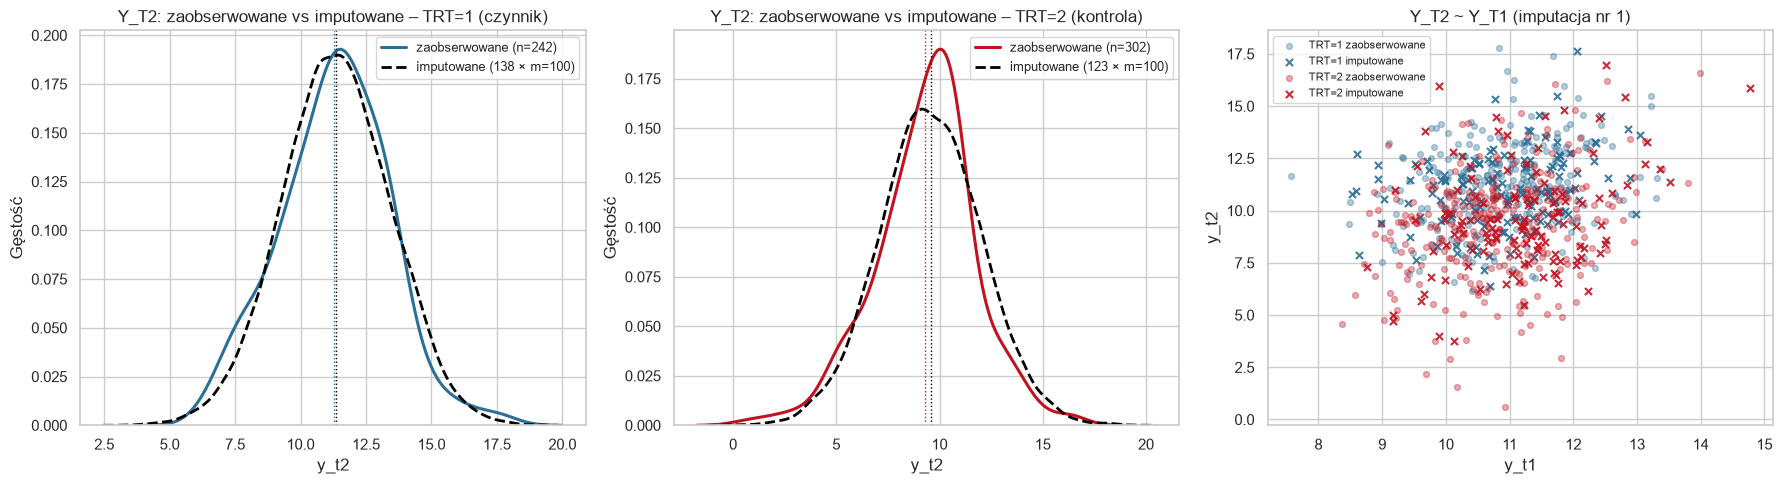

In [21]:
Y2 = p3.wielokrotna_imputacja(df, m=M_IMP, seed=SEED)

print("Oszacowania parametrów modeli imputacyjnych (OLS na danych kompletnych w warstwach TRT):")
for g in [1, 2]:
    dg = df.loc[(df["trt"] == g) & ~df["brak_y_t2"]]
    rg = smf.ols("y_t2 ~ y_t1 + x1 + x2", data=dg).fit()
    print(f"\nTRT={g}: n_obs = {int(rg.nobs)}, sigma_hat = {np.sqrt(rg.mse_resid):.4f}, R² = {rg.rsquared:.4f}")
    display(pd.DataFrame({"gamma_hat": rg.params, "SE": rg.bse, "p-value": rg.pvalues}).round(4))

fig6 = p3.wykres_diagnostyka_imputacji(df, Y2, plik=FIG / "fig6_imputacja_diagnostyka.png")
plt.show()

In [22]:
mar = p3.analiza_mar(df, Y2, alpha=ALPHA)
print(f"N = {mar['n']}, m = {mar['m']}, R² (Fisher z) = {mar['r2']:.4f}, RMSE = {mar['rmse']:.4f}, "
      f"referencyjne Y_T1 = {mar['y1_ref']:.4f}")

print("\nWspółczynniki ANCOVA (MAR – reguły Rubina, poprawka Barnarda-Rubina):")
display(mar["wsp"].round(4))

print("\nŚrednie CHG surowe i LS-means (MAR – reguły Rubina):")
display(mar["srednie"].round(4))

# Weryfikacja krzyżowa z scikit-learn IterativeImputer(BayesianRidge, sample_posterior=True)
Y2_sk = p3.wielokrotna_imputacja_sklearn(df, m=M_IMP, seed=SEED)
mar_sk = p3.analiza_mar(df, Y2_sk, alpha=ALPHA)
print("\nWeryfikacja krzyżowa: IterativeImputer(BayesianRidge, sample_posterior=True), warstwy TRT:")
display(mar_sk["wsp"][["Oszacowanie", "SE", "df (ν_adj)", "p-value", "CI 2.5%", "CI 97.5%", "FMI"]].round(4))

# Testy poprawności technicznej
model_fast = p3.SzybkaANCOVA(df)
B_fast, V_fast = model_fast.dopasuj(Y2)
obs_y2 = df.loc[~brak, "y_t2"].to_numpy()
Y_test = p3.przesun_mnar(Y2, brak, trt, -3.0, 1.5)

assert not np.isnan(Y2).any(), "Wykryto wartości NaN po imputacji!"
assert np.all(Y2[~brak, :] == obs_y2[:, None]), "Zmodyfikowano wartości zaobserwowane!"
assert np.all(Y2[brak, :].std(axis=1) > 0), "Brak zmienności międzyimputacyjnej!"
assert np.allclose(B_fast, mar["Q_beta"]) and np.allclose(V_fast, mar["U_beta"]), "Niezgodność SzybkaANCOVA!"
assert np.all(Y_test[~brak, :] == Y2[~brak, :]), "MNAR zmieniło wartości zaobserwowane!"
print("\n[OK] Wszystkie testy kontrolne imputacji, reguł Rubina i izolacji maski MNAR zakończone sukcesem.")

N = 805, m = 100, R² (Fisher z) = 0.1900, RMSE = 2.2031, referencyjne Y_T1 = 10.8860

Współczynniki ANCOVA (MAR – reguły Rubina, poprawka Barnarda-Rubina):


,Oszacowanie,SE,t,df (ν_adj),p-value,CI 2.5%,CI 97.5%,W,B,T,RIV,λ,FMI
β0 (wyraz wolny),2.8181,1.0469,2.6919,347.6592,0.0074,0.7591,4.8772,0.7448,0.3477,1.0960,0.4715,0.3204,0.3243
β1 (TRT=1 vs TRT=2),1.9594,0.1871,10.4741,361.4494,0.0000,1.5915,2.3273,0.0242,0.0107,0.0350,0.4456,0.3082,0.3120
β2 (Y_T1),-0.3977,0.0960,-4.1411,335.1658,0.0000,-0.5866,-0.2088,0.0062,0.0030,0.0092,0.4968,0.3319,0.3358



Średnie CHG surowe i LS-means (MAR – reguły Rubina):


,Oszacowanie,SE,t,df (ν_adj),p-value,CI 2.5%,CI 97.5%,W,B,T,RIV,λ,FMI
CHG surowa – TRT=1,0.4587,0.1294,3.5452,195.8260,0.0005,0.2035,0.7139,0.0112,0.0055,0.0167,0.5010,0.3338,0.3405
CHG surowa – TRT=2,-1.5205,0.1390,-10.9368,228.6791,0.0000,-1.7945,-1.2466,0.0134,0.0059,0.0193,0.4433,0.3071,0.3131
LS-mean CHG – TRT=1,0.4483,0.1356,3.3062,365.2876,0.0010,0.1816,0.7149,0.0128,0.0056,0.0184,0.4387,0.3049,0.3087
LS-mean CHG – TRT=2,-1.5112,0.1316,-11.4821,326.1521,0.0000,-1.7701,-1.2522,0.0114,0.0058,0.0173,0.5162,0.3405,0.3445



Weryfikacja krzyżowa: IterativeImputer(BayesianRidge, sample_posterior=True), warstwy TRT:


,Oszacowanie,SE,df (ν_adj),p-value,CI 2.5%,CI 97.5%,FMI
β0 (wyraz wolny),3.0753,1.0021,422.3331,0.0023,1.1055,5.0450,0.2629
β1 (TRT=1 vs TRT=2),1.9493,0.1774,461.2149,0.0000,1.6007,2.2978,0.2349
β2 (Y_T1),-0.4216,0.0918,409.4881,0.0000,-0.6020,-0.2413,0.2727



[OK] Wszystkie testy kontrolne imputacji, reguł Rubina i izolacji maski MNAR zakończone sukcesem.


### Interpretacja wyników (MAR – imputacja wielokrotna i reguły Rubina)

- **Diagnostyka imputacji (`fig6` i regresje warstwowe):** wyimputowane wartości $Y_{T2}$ w obu warstwach dobrze odwzorowują kształt oraz rozproszenie rozkładów zaobserwowanych ($\hat{\sigma}_1 = 2{,}0098$ w `TRT=1`, $\hat{\sigma}_2 = 2{,}3578$ w `TRT=2`). Nieznaczne przesunięcie średnich imputacji wynika z wyższego poziomu wyjściowego $Y_{T1}$ u jednostek z brakami (mechanizm MAR wykryty w punkcie 2).
- **Średnie zmiany `CHG` po imputacji ($N = 805, m = 100$):** po połączeniu regułami Rubina surowa średnia zmiana wynosi **$+0{,}4587$** ($\text{SE} = 0{,}1294$; 95% CI: $[0{,}2035; 0{,}7139]$) w `TRT=1` oraz **$-1{,}5205$** ($\text{SE} = 0{,}1390$; 95% CI: $[-1{,}7945; -1{,}2466]$) w `TRT=2`. Skorygowane średnie brzegowe (*LS-means* przy $\bar{Y}_{T1} = 10{,}8860$ dla całej próby) to odpowiednio **$+0{,}4483$** oraz **$-1{,}5112$**.
- **Model ANCOVA (MAR):** efekt czynnika wynosi **$\hat{\beta}_1 = 1{,}9594$** ($\text{SE} = 0{,}1871$, $t = 10{,}4741$, $\nu_{\text{adj}} = 361{,}45$, $p = 1{,}35 \cdot 10^{-22}$, 95% CI: $[1{,}5915; 2{,}3273]$), a parametr kowarianty $\hat{\beta}_2 = -0{,}3977$ ($p = 4{,}38 \cdot 10^{-5}$). Łączony współczynnik determinacji wzrósł do $R^2 = 19{,}00\%$, a błąd standardowy $\text{SE}(\beta_1)$ spadł z $0{,}1901$ (CC) do $0{,}1871$ (MI) dzięki wykorzystaniu pełnej próby $N = 805$.
- **Analiza wariancji Rubina:** wariancja międzyimputacyjna jest niezerowa ($B(\beta_1) = 0{,}0107 > 0$ przy wariancji wewnątrzimputacyjnej $W = 0{,}0242$ i całkowitej $T = 0{,}0350$), co potwierdza prawidłowe uwzględnienie niepewności imputacji. Udział brakującej informacji wynosi $\text{FMI}(\beta_1) = 31{,}20\%$ ($\text{RIV} = 0{,}4456$), co dobrze odpowiada udziałowi braków w danych ($32{,}42\%$).
- **Weryfikacja krzyżowa (`sklearn`):** niezależny algorytm `IterativeImputer(BayesianRidge, sample_posterior=True)` daje niemal identyczne oszacowanie $\hat{\beta}_1 = 1{,}9493$ ($\text{SE} = 0{,}1774$, 95% CI: $[1{,}6007; 2{,}2978]$), potwierdzając stabilność wyników względem metody estymacji bayesowskiej.

## 4. Scenariusz MNAR – korekta $\delta$-adjustment i 1D *tipping-point analysis*

Ponieważ w scenariuszu MAR oszacowany efekt $\hat{\beta}_1 = 1{,}9594$ ($p = 1{,}35 \cdot 10^{-22}$) jest wysoce istotny statystycznie i dodatni, testujemy odchylenia MNAR podważające ten wniosek – przesuwamy w dół ($\delta < 0$) **wyłącznie** wyimputowane wartości $Y_{T2}$ w grupie badanej (`TRT=1`, $n_{\text{mis}} = 138$):
$$
Y_{T2,i}^{\text{MNAR}}(\delta) = \begin{cases} Y_{T2,i}^{\text{MAR}} + \delta, & \text{gdy brak } Y_{T2,i} \text{ oraz } \text{TRT}_i = 1, \\ Y_{T2,i}, & \text{w przeciwnym razie (obserwacje zaobserwowane oraz TRT=2 bez zmian).} \end{cases}
$$
Następnie szukamy dokładnego punktu krytycznego $\delta^*$, w którym dwustronne $p\text{-value}(\delta^*) = 0{,}05$, oraz oceniamy jego skalę względem odchyleń standardowych $Y_{T2}$, $\text{CHG}$ i różnicy między grupami.

Zgrubna siatka δ (co 0.5):


,δ,β1,SE,CI 2.5%,CI 97.5%,p-value,FMI,Decyzja (α=0.05)
0,0.0,1.9594,0.1871,1.5915,2.3273,0.0000,0.3120,odrzucamy H0
1,-0.5,1.7777,0.1874,1.4092,2.1462,0.0000,0.3110,odrzucamy H0
2,-1.0,1.5960,0.1884,1.2255,1.9665,0.0000,0.3076,odrzucamy H0
3,-1.5,1.4143,0.1902,1.0403,1.7882,0.0000,0.3020,odrzucamy H0
4,-2.0,1.2325,0.1926,0.8538,1.6113,0.0000,0.2944,odrzucamy H0
5,-2.5,1.0508,0.1957,0.6660,1.4356,0.0000,0.2852,odrzucamy H0
6,-3.0,0.8691,0.1995,0.4769,1.2612,0.0000,0.2746,odrzucamy H0
7,-3.5,0.6874,0.2038,0.2867,1.0880,0.0008,0.2631,odrzucamy H0
8,-4.0,0.5056,0.2088,0.0954,0.9159,0.0158,0.2509,odrzucamy H0
9,-4.5,0.3239,0.2142,-0.0970,0.7449,0.1312,0.2384,brak podstaw do odrzucenia H0


Zagęszczona siatka w przedziale przejścia (co 0.05):


,δ,β1,SE,CI 2.5%,CI 97.5%,p-value,FMI,Decyzja (α=0.05)
0,-4.50,0.3239,0.2142,-0.0970,0.7449,0.1312,0.2384,brak podstaw do odrzucenia H0
1,-4.45,0.3421,0.2136,-0.0777,0.7619,0.1100,0.2397,brak podstaw do odrzucenia H0
2,-4.40,0.3603,0.2131,-0.0585,0.7790,0.0916,0.2410,brak podstaw do odrzucenia H0
3,-4.35,0.3784,0.2125,-0.0392,0.7961,0.0756,0.2422,brak podstaw do odrzucenia H0
4,-4.30,0.3966,0.2120,-0.0200,0.8132,0.0620,0.2435,brak podstaw do odrzucenia H0
5,-4.25,0.4148,0.2114,-0.0007,0.8303,0.0504,0.2447,brak podstaw do odrzucenia H0
6,-4.20,0.4330,0.2109,0.0185,0.8474,0.0406,0.2460,odrzucamy H0
7,-4.15,0.4511,0.2103,0.0377,0.8645,0.0325,0.2472,odrzucamy H0
8,-4.10,0.4693,0.2098,0.0570,0.8816,0.0258,0.2485,odrzucamy H0
9,-4.05,0.4875,0.2093,0.0762,0.8988,0.0203,0.2497,odrzucamy H0


>>> PUNKT KRYTYCZNY (Brent): δ* = -4.2481
    β1(δ*) = 0.4155, SE = 0.2114, 95% CI = [0.0000; 0.8309], p = 0.050000
    Punkt zerowania efektu β1(δ0) = 0: δ0 = -5.3912 (nachylenie c = 0.3634)


,wartość
δ*,-4.2481
"SD(Y_T2) obs., cała próba",2.4829
"SD(Y_T2) obs., TRT=1",2.0760
"SD(CHG) obs., cała próba",2.4327
"SD(CHG) obs., TRT=1",2.0497
RMSE ANCOVA (MAR),2.2031
δ* / SD(Y_T2),-1.7110
δ* / SD(Y_T2 | TRT=1),-2.0463
δ* / SD(CHG),-1.7463
δ* / SD(CHG | TRT=1),-2.0726


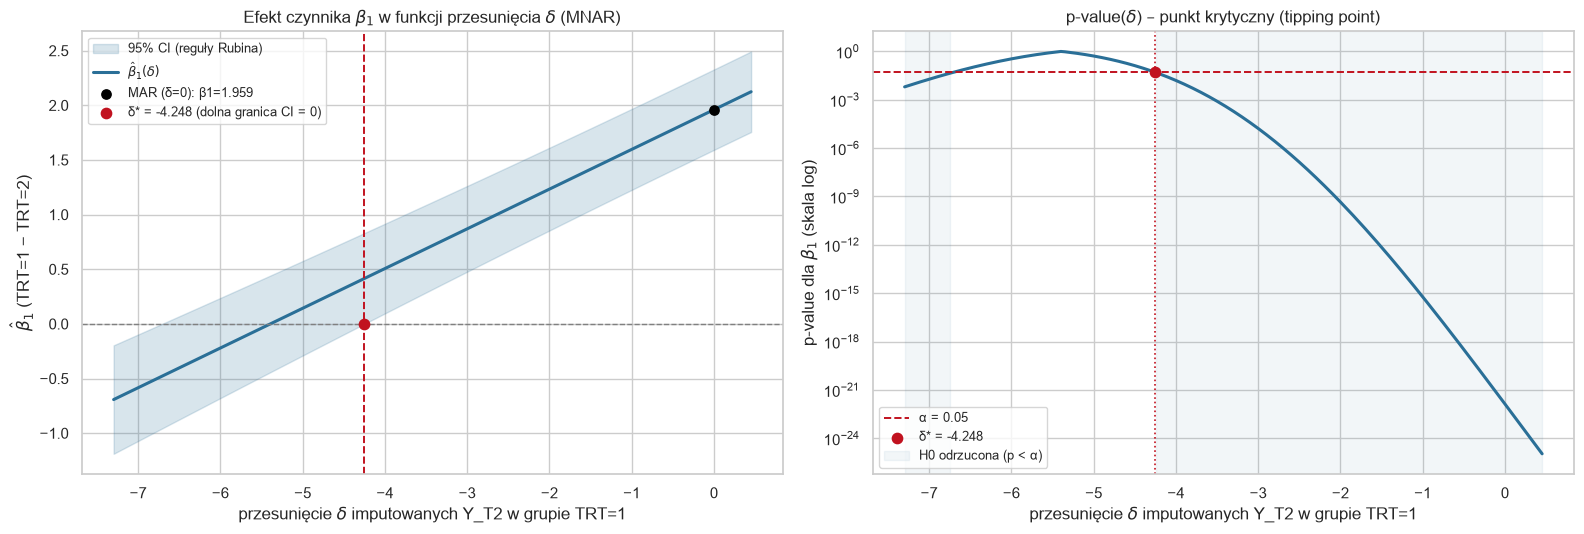

In [23]:
tp1 = p3.tipping_point_1d(model_fast, Y2, brak, trt, mar["wsp"], krok=p3.KROK_DELTA, alpha=ALPHA)

print("Zgrubna siatka δ (co 0.5):")
display(tp1["zgrubna"].round(4))

print("Zagęszczona siatka w przedziale przejścia (co 0.05):")
display(tp1["gesta"].round(4))

ws = tp1["wynik_star"]
print(f">>> PUNKT KRYTYCZNY (Brent): δ* = {tp1['delta_star']:.4f}")
print(f"    β1(δ*) = {ws['β1']:.4f}, SE = {ws['SE']:.4f}, 95% CI = [{ws['CI 2.5%']:.4f}; {ws['CI 97.5%']:.4f}], p = {ws['p-value']:.6f}")
print(f"    Punkt zerowania efektu β1(δ0) = 0: δ0 = {tp1['delta_zero']:.4f} (nachylenie c = {tp1['c']:.4f})")

# Wskaźniki skali δ* (realizm scenariusza MNAR)
sd_y2, sd_y2_1 = df["y_t2"].std(), df.loc[df["trt"] == 1, "y_t2"].std()
sd_chg, sd_chg_1 = df["chg"].std(), df.loc[df["trt"] == 1, "chg"].std()
ds = tp1["delta_star"]
chg_imp_1 = (Y2[brak & (trt == 1)] - df.loc[brak & (trt == 1), "y_t1"].to_numpy()[:, None]).mean()
chg_obs_1 = df.loc[(trt == 1) & ~brak, "chg"].mean()
chg_obs_2 = df.loc[(trt == 2) & ~brak, "chg"].mean()
chg_mar_2 = mar["srednie"].loc["CHG surowa – TRT=2", "Oszacowanie"]

skala = pd.DataFrame({
    "wartość": [ds, sd_y2, sd_y2_1, sd_chg, sd_chg_1, mar["rmse"], ds / sd_y2, ds / sd_y2_1,
                ds / sd_chg, ds / sd_chg_1, ds / mar["rmse"], chg_obs_1, chg_imp_1, chg_imp_1 + ds,
                chg_obs_2, chg_mar_2, chg_mar_2 - chg_imp_1],
}, index=[
    "δ*", "SD(Y_T2) obs., cała próba", "SD(Y_T2) obs., TRT=1", "SD(CHG) obs., cała próba",
    "SD(CHG) obs., TRT=1", "RMSE ANCOVA (MAR)", "δ* / SD(Y_T2)", "δ* / SD(Y_T2 | TRT=1)",
    "δ* / SD(CHG)", "δ* / SD(CHG | TRT=1)", "δ* / RMSE",
    "Śr. CHG zaobserwowana, TRT=1", "Śr. CHG imputowana (MAR), braki TRT=1",
    "Śr. CHG imputowana przy δ*, braki TRT=1", "Śr. CHG zaobserwowana, TRT=2",
    "Śr. CHG (MAR), TRT=2 – cała grupa", "δ_ref: braki TRT=1 -> średnia CHG grupy kontrolnej",
])
display(skala.round(4))

delty_plot = np.round(np.arange(min(0.0, 1.6 * ds, 1.1 * tp1["delta_zero"]) - 0.5,
                                max(0.0, 1.6 * ds, 1.1 * tp1["delta_zero"]) + 0.5 + 1e-9, 0.05), 4)
siatka_1d = p3.siatka_1d(model_fast, Y2, brak, trt, delty_plot, alpha=ALPHA)
fig7 = p3.wykres_tipping_1d(siatka_1d, tp1, mar["wsp"], alpha=ALPHA, plik=FIG / "fig7_tipping_point_1d.png")
plt.show()

### Interpretacja punktu krytycznego 1D i ocena realizmu scenariusza MNAR

- **Punkt krytyczny $\delta^*$:** wraz ze spadkiem $\delta$ (pogarszaniem wyników wyłącznie $138$ brakujących obserwacji w `TRT=1`) oszacowanie $\hat{\beta}_1(\delta)$ maleje liniowo zgodnie ze wzorem $\hat{\beta}_1(\delta) = 1{,}9594 + 0{,}3634\,\delta$. Dolna granica 95% przedziału ufności przecina zero ($p = 0{,}0500$) dopiero w punkcie **$\delta^* = -4{,}2481$**, gdzie $\hat{\beta}_1(\delta^*) = 0{,}4155$ ($\text{SE} = 0{,}2114$, 95% CI: $[0{,}0000; 0{,}8309]$). Całkowite wyzerowanie efektu wymagałoby przesunięcia $\delta_0 = -5{,}3912$, a dla $\delta < -6{,}77$ krzywa $p(\delta)$ na `fig7` ponownie schodzi poniżej $\alpha = 0{,}05$ – odpowiada to odwróceniu znaku wniosku (przewaga grupy kontrolnej).
- **Ocena realizmu merytorycznego:**
  1. Przesunięcie $\delta^* = -4{,}2481$ odpowiada aż **$-2{,}05$ odchylenia standardowego $Y_{T2}$ w grupie `TRT=1`** ($\text{SD} = 2{,}0760$), **$-2{,}07\,\text{SD}(\text{CHG} \mid \text{TRT}=1)$** ($\text{SD} = 2{,}0497$) oraz **$-1{,}93\,\text{RMSE}$** modelu ANCOVA.
  2. Przy tak silnym mechanizmie MNAR średnia zmiana `CHG` wśród osób z brakami w grupie z czynnikiem musiałaby wynosić **$-3{,}7794$**, podczas gdy wśród osób zaobserwowanych w `TRT=1` wynosi ona $+0{,}4530$, a w całej grupie kontrolnej `TRT=2` $-1{,}5205$.
  3. Nawet w bardzo konserwatywnym scenariuszu *jump-to-reference*, w którym jednostki z brakami w `TRT=1` osiągałyby identyczną zmianę jak grupa kontrolna ($\delta_{\text{ref}} = -1{,}9893$), efekt czynnika pozostaje wysoce istotny ($\hat{\beta}_1 \approx 1{,}24$, $p \ll 0{,}001$).
- **Wniosek:** aby podważyć istotność dodatniego efektu czynnika `TRT=1`, niezaobserwowane jednostki w tej grupie musiałyby wypaść ponad dwukrotnie gorzej od przeciętnego spadku w grupie kontrolnej. Taki scenariusz MNAR jest **merytorycznie nierealistyczny**, co świadczy o wysokiej odporności wniosku głównego.

## 5. Aspekt innowacyjny – dwuwymiarowa analiza punktu krytycznego (2D *tipping-point analysis*)

W praktyce mechanizm MNAR może działać jednocześnie w obu grupach badania: osoby rezygnujące w grupie z czynnikiem (`TRT=1`) mogą uzyskiwać wynik inny o $\delta_1$, a osoby rezygnujące w grupie kontrolnej (`TRT=2`) inny o $\delta_2$. Badamy siatkę $(\delta_1, \delta_2) \in [-7; 7]^2$ ($121 \times 121 = 14\,641$ kombinacji, dla każdej estymujemy $m=100$ modeli ANCOVA i łączymy je regułami Rubina) oraz wyznaczamy krzywą graniczną $p(\delta_1, \delta_2) = 0{,}05$.

Krytyczne przesunięcie δ1*(δ2) w TRT=1 dla wybranych przesunięć δ2 w TRT=2:


,δ2 (TRT=2),δ1* (TRT=1)
0,-2.0,-5.7097
1,-1.0,-4.9869
2,0.0,-4.2481
3,1.0,-3.4907
4,2.0,-2.7124
5,3.0,-1.9119


,δ1 (TRT=1),δ2 (TRT=2),β1,SE,CI 2.5%,CI 97.5%,p-value,FMI,Decyzja (α=0.05)
0,-2,0,1.2325,0.1926,0.8538,1.6113,0.0000,0.2944,odrzucamy H0
1,-4,0,0.5056,0.2088,0.0954,0.9159,0.0158,0.2509,odrzucamy H0
2,-4,2,-0.0693,0.2140,-0.4899,0.3514,0.7463,0.2388,brak podstaw do odrzucenia H0
3,-2,2,0.6576,0.1983,0.2677,1.0475,0.0010,0.2778,odrzucamy H0
4,0,2,1.3845,0.1929,1.0052,1.7638,0.0000,0.2935,odrzucamy H0
5,0,4,0.8096,0.2091,0.3986,1.2205,0.0001,0.2501,odrzucamy H0
6,-6,0,-0.2213,0.2333,-0.6796,0.2371,0.3434,0.2013,brak podstaw do odrzucenia H0
7,-4,-2,1.0806,0.2136,0.6608,1.5004,0.0000,0.2397,odrzucamy H0
8,2,2,2.1114,0.1987,1.7208,2.5020,0.0000,0.2769,odrzucamy H0
9,-3,3,0.0067,0.2115,-0.4090,0.4224,0.9747,0.2444,brak podstaw do odrzucenia H0


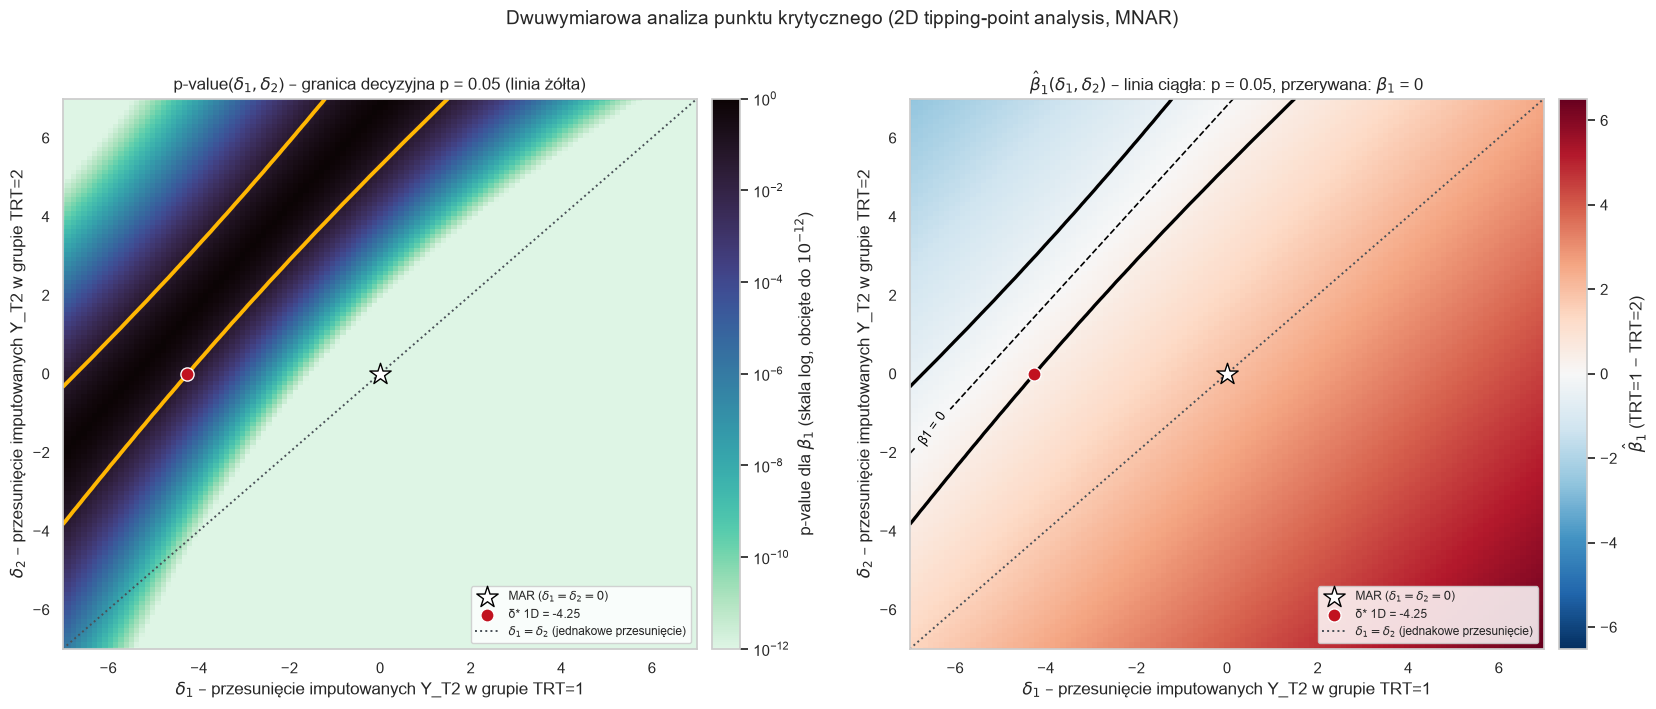

In [24]:
R = float(np.ceil(1.5 * abs(tp1["delta_star"])))
grid_2d = np.round(np.linspace(-R, R, 121), 6)
tp2 = p3.tipping_point_2d(model_fast, Y2, brak, trt, grid_2d, grid_2d, alpha=ALPHA)

d2_tab = [-2.0, -1.0, 0.0, 1.0, 2.0, 3.0]
kryt_2d = p3.krytyczne_delta1(model_fast, Y2, brak, trt, d2_tab, tp1["kierunek"], alpha=ALPHA)
print("Krytyczne przesunięcie δ1*(δ2) w TRT=1 dla wybranych przesunięć δ2 w TRT=2:")
display(kryt_2d.round(4))

wybrane = [(-2, 0), (-4, 0), (-4, 2), (-2, 2), (0, 2), (0, 4), (-6, 0), (-4, -2), (2, 2), (-3, 3)]
tab_2d = pd.DataFrame([
    {**{"δ1 (TRT=1)": a, "δ2 (TRT=2)": b},
     **{k: v for k, v in p3._wiersz(np.nan, p3.beta1_mnar(model_fast, Y2, brak, trt, a, b, alpha=ALPHA), alpha=ALPHA).items()
        if k != "δ"}}
    for a, b in wybrane
])
display(tab_2d.round(4))

fig8 = p3.wykres_tipping_2d(tp2, tp1, alpha=ALPHA, plik=FIG / "fig8_tipping_point_2d.png")
plt.show()

### Interpretacja analizy dwuwymiarowej (2D *tipping-point analysis*)

- Mapa ciepła (`fig8`) obrazuje jednoczesne oddziaływanie mechanizmu MNAR w obu grupach ($\delta_1$ dla `TRT=1`, $\delta_2$ dla `TRT=2`).
- **Symetryczny mechanizm MNAR ($\delta_1 = \delta_2$, linia kropkowana):** w całym badanym zakresie $[-7; +7]$ leży głęboko w obszarze odrzucenia $H_0$ ($p < 0{,}05$), gdyż jednakowe odchylenie w obu grupach znosi się w różnicy $\beta_1$.
- **Asymetryczne scenariusze graniczne:** jeśli w grupie kontrolnej braki byłyby zawyżone o $\delta_2 = +2{,}0$, punkt krytyczny w grupie z czynnikiem przesuwa się z $\delta_1^* = -4{,}25$ do $\delta_1^* = -2{,}7124$ (nadal wymagałoby to jednak silnych, przeciwnie skierowanych odchyleń MNAR jednocześnie w obu ramionach badania).

## 6. Podsumowanie porównawcze: MCAR vs MAR vs MNAR

,MCAR (CC),"MAR (MI, FCS norm)","MAR (MI, sklearn)"
N,544.0000,805.0000,805.0000
Śr. CHG surowa TRT=1,0.4530,0.4587,0.4458
Śr. CHG surowa TRT=2,-1.4898,-1.5205,-1.5245
LS-mean CHG TRT=1,0.4603,0.4483,0.4347
LS-mean CHG TRT=2,-1.4956,-1.5112,-1.5145
β1,1.9559,1.9594,1.9493
SE(β1),0.1901,0.1871,0.1774
CI 2.5%,1.5824,1.5915,1.6007
CI 97.5%,2.3293,2.3273,2.2978
p-value,0.0000,0.0000,0.0000


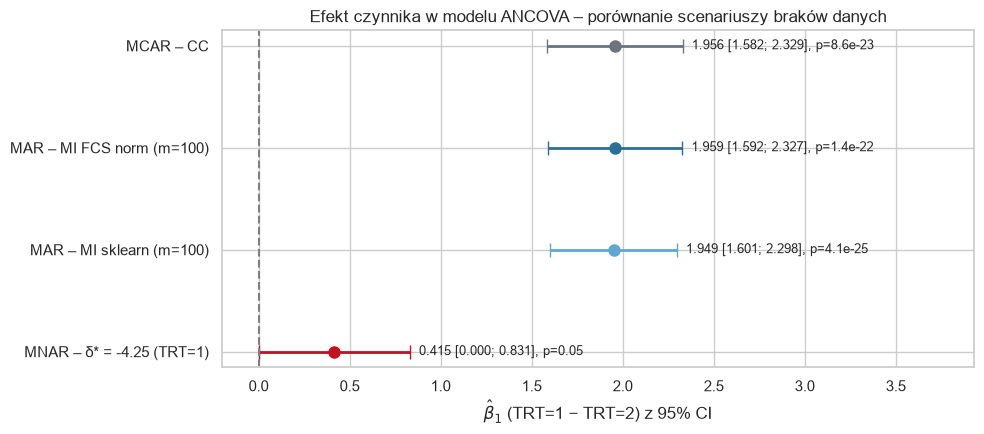

In [25]:
comp = pd.DataFrame({
    "MCAR (CC)": [mcar["n"], mcar["srednie"].iloc[0, 0], mcar["srednie"].iloc[1, 0],
                  mcar["srednie"].iloc[2, 0], mcar["srednie"].iloc[3, 0],
                  *mcar["wsp"].iloc[1][["Oszacowanie", "SE", "CI 2.5%", "CI 97.5%", "p-value"]],
                  mcar["wsp"].iloc[2]["Oszacowanie"], mcar["r2"], np.nan, np.nan],
    "MAR (MI, FCS norm)": [mar["n"], *mar["srednie"]["Oszacowanie"],
                           *mar["wsp"].iloc[1][["Oszacowanie", "SE", "CI 2.5%", "CI 97.5%", "p-value"]],
                           mar["wsp"].iloc[2]["Oszacowanie"], mar["r2"], mar["wsp"].iloc[1]["RIV"],
                           mar["wsp"].iloc[1]["FMI"]],
    "MAR (MI, sklearn)": [mar_sk["n"], *mar_sk["srednie"]["Oszacowanie"],
                          *mar_sk["wsp"].iloc[1][["Oszacowanie", "SE", "CI 2.5%", "CI 97.5%", "p-value"]],
                          mar_sk["wsp"].iloc[2]["Oszacowanie"], mar_sk["r2"], mar_sk["wsp"].iloc[1]["RIV"],
                          mar_sk["wsp"].iloc[1]["FMI"]],
}, index=["N", "Śr. CHG surowa TRT=1", "Śr. CHG surowa TRT=2", "LS-mean CHG TRT=1",
          "LS-mean CHG TRT=2", "β1", "SE(β1)", "CI 2.5%", "CI 97.5%", "p-value", "β2 (Y_T1)", "R²",
          "RIV(β1)", "FMI(β1)"])
display(comp.round(4))

forest = pd.DataFrame([
    {"β1": mcar["wsp"].iloc[1]["Oszacowanie"], "CI 2.5%": mcar["wsp"].iloc[1]["CI 2.5%"],
     "CI 97.5%": mcar["wsp"].iloc[1]["CI 97.5%"], "p-value": mcar["wsp"].iloc[1]["p-value"]},
    {"β1": mar["wsp"].iloc[1]["Oszacowanie"], "CI 2.5%": mar["wsp"].iloc[1]["CI 2.5%"],
     "CI 97.5%": mar["wsp"].iloc[1]["CI 97.5%"], "p-value": mar["wsp"].iloc[1]["p-value"]},
    {"β1": mar_sk["wsp"].iloc[1]["Oszacowanie"], "CI 2.5%": mar_sk["wsp"].iloc[1]["CI 2.5%"],
     "CI 97.5%": mar_sk["wsp"].iloc[1]["CI 97.5%"], "p-value": mar_sk["wsp"].iloc[1]["p-value"]},
    {k: ws[k] for k in ["β1", "CI 2.5%", "CI 97.5%", "p-value"]},
], index=["MCAR – CC", f"MAR – MI FCS norm (m={M_IMP})", f"MAR – MI sklearn (m={M_IMP})",
          f"MNAR – δ* = {tp1['delta_star']:.2f} (TRT=1)"])
fig9 = p3.wykres_forest(forest, plik=FIG / "fig9_forest_beta1.png")
plt.show()

### Wnioski podsumowujące dla Punktu 3

1. Wyniki modeli **MCAR (Complete-Case: $\hat{\beta}_1 = 1{,}9559$)** oraz **MAR (MI FCS/MICE: $\hat{\beta}_1 = 1{,}9594$, $m=100$)** są bardzo zbieżne i jednoznacznie wskazują na istotny, dodatni efekt czynnika `TRT=1` w porównaniu z grupą kontrolną `TRT=2` ($p < 10^{-21}$).
2. Zastosowanie imputacji wielokrotnej w wariancie warstwowym z pełnym zbiorem predyktorów (`y_t1`, `x1`, `x2`) pozwoliło uniknąć odrzucenia $32{,}42\%$ próby, zmniejszyło błąd standardowy $\text{SE}(\beta_1)$ i poprawnie uwzględniło niepewność braków danych ($\text{FMI} = 31{,}20\%$).
3. Analiza wrażliwości MNAR wykazała, że obalenie istotności efektu wymagałoby przesunięcia o $\delta^* = -4{,}2481$ ($\approx -2{,}05\,\text{SD}$) w `TRT=1`, co jest skrajnie mało prawdopodobne merytorycznie – konkluzja o skuteczności czynnika jest więc w pełni stabilna.

---

# Punkt 4. Podsumowanie wyników estymacji modelu właściwego w kontekście braków danych

### Cel i metoda analizy

Weryfikujemy, czy czynnik `TRT` różnicuje zmianę badanej cechy pomiędzy pomiarami, przy uwzględnieniu wartości wyjściowej. Zmienna celu oraz model ANCOVA mają postać:

$$
CHG_i=Y_{T2,i}-Y_{T1,i},\qquad
CHG_i=\beta_0+\beta_1 I(TRT_i=1)+\beta_2Y_{T1,i}+\varepsilon_i.
$$

Grupa `TRT=2` jest kategorią referencyjną. Parametr $\beta_1$ oznacza zatem **skorygowaną różnicę przeciętnej zmiany `CHG` między grupą z czynnikiem (`TRT=1`) i kontrolą (`TRT=2`)**, przy tej samej wartości $Y_{T1}$. Sprawdzamy hipotezę $H_0:\beta_1=0$ wobec $H_1:\beta_1\ne0$ dla $\alpha=0{,}05$.

W próbie $N=805$ brakuje 261 pomiarów końcowych $Y_{T2}$ (32,42%), a więc także 261 wartości pochodnej zmiennej `CHG`. Porównujemy wyniki z punktu 3 uzyskane metodą **pełnych przypadków (CC)**, **imputacji wielokrotnej przy założeniu MAR (MI, $m=100$)** oraz w **analizie wrażliwości MNAR**. Termin „MCAR (CC)” w tabelach oznacza wariant analityczny oparty na pełnych przypadkach, a nie potwierdzenie prawdziwości założenia MCAR.

Ocenę skutków braków opieramy nie tylko na wielkości oszacowań, lecz również na ich **niepewności i stabilności wobec założeń**. W MI wariancja połączonego estymatora, wyznaczana zgodnie z regułami Rubina, wynosi:

$$
T=\overline U+\left(1+\frac{1}{m}\right)B,
$$

gdzie $\overline U$ oznacza średnią wariancję wewnątrzimputacyjną, a $B$ — wariancję międzyimputacyjną. Dlatego porównujemy oceny parametrów, błędy standardowe, 95% przedziały ufności i decyzje weryfikacyjne, a także frakcję brakującej informacji (FMI).

Tabela 4.1. Porównanie ocen modelu ANCOVA — CC i MI przy MAR:


,MCAR (CC),"MAR (MI, FCS norm)"
N,544,805
β0,2.7225,2.8181
β1 (TRT=1 vs 2),1.9559,1.9594
SE(β1),0.1901,0.1871
95% CI β1 — dolna,1.5824,1.5915
95% CI β1 — górna,2.3293,2.3273
p(β1),8.60e-23,1.35e-22
β2 (Y_T1),-0.3898,-0.3977
p(β2),5.56e-05,4.38e-05
R²,0.1827,0.1900


Różnica ocen β1 (MI − CC): +0.0036; zmiana SE(β1): −1.60%
Weryfikacja alternatywną MI (sklearn): β1 = 1.9493
MNAR 1D: δ* = -4.2481, przesunięto 138 braków Y_T2 w TRT=1
|δ*| / SD zaobserwowanych Y_T2 w TRT=1 = 2.05
Tabela 4.2. Punkty krytyczne δ1* w zależności od przesunięcia δ2 w grupie kontrolnej:


,δ2 (TRT=2),δ1* (TRT=1)
0,-2.0,-5.7097
1,-1.0,-4.9869
2,0.0,-4.2481
3,1.0,-3.4907
4,2.0,-2.7124
5,3.0,-1.9119


Rysunek 4.1. Efekt TRT i 95% przedziały ufności w rozważanych podejściach:


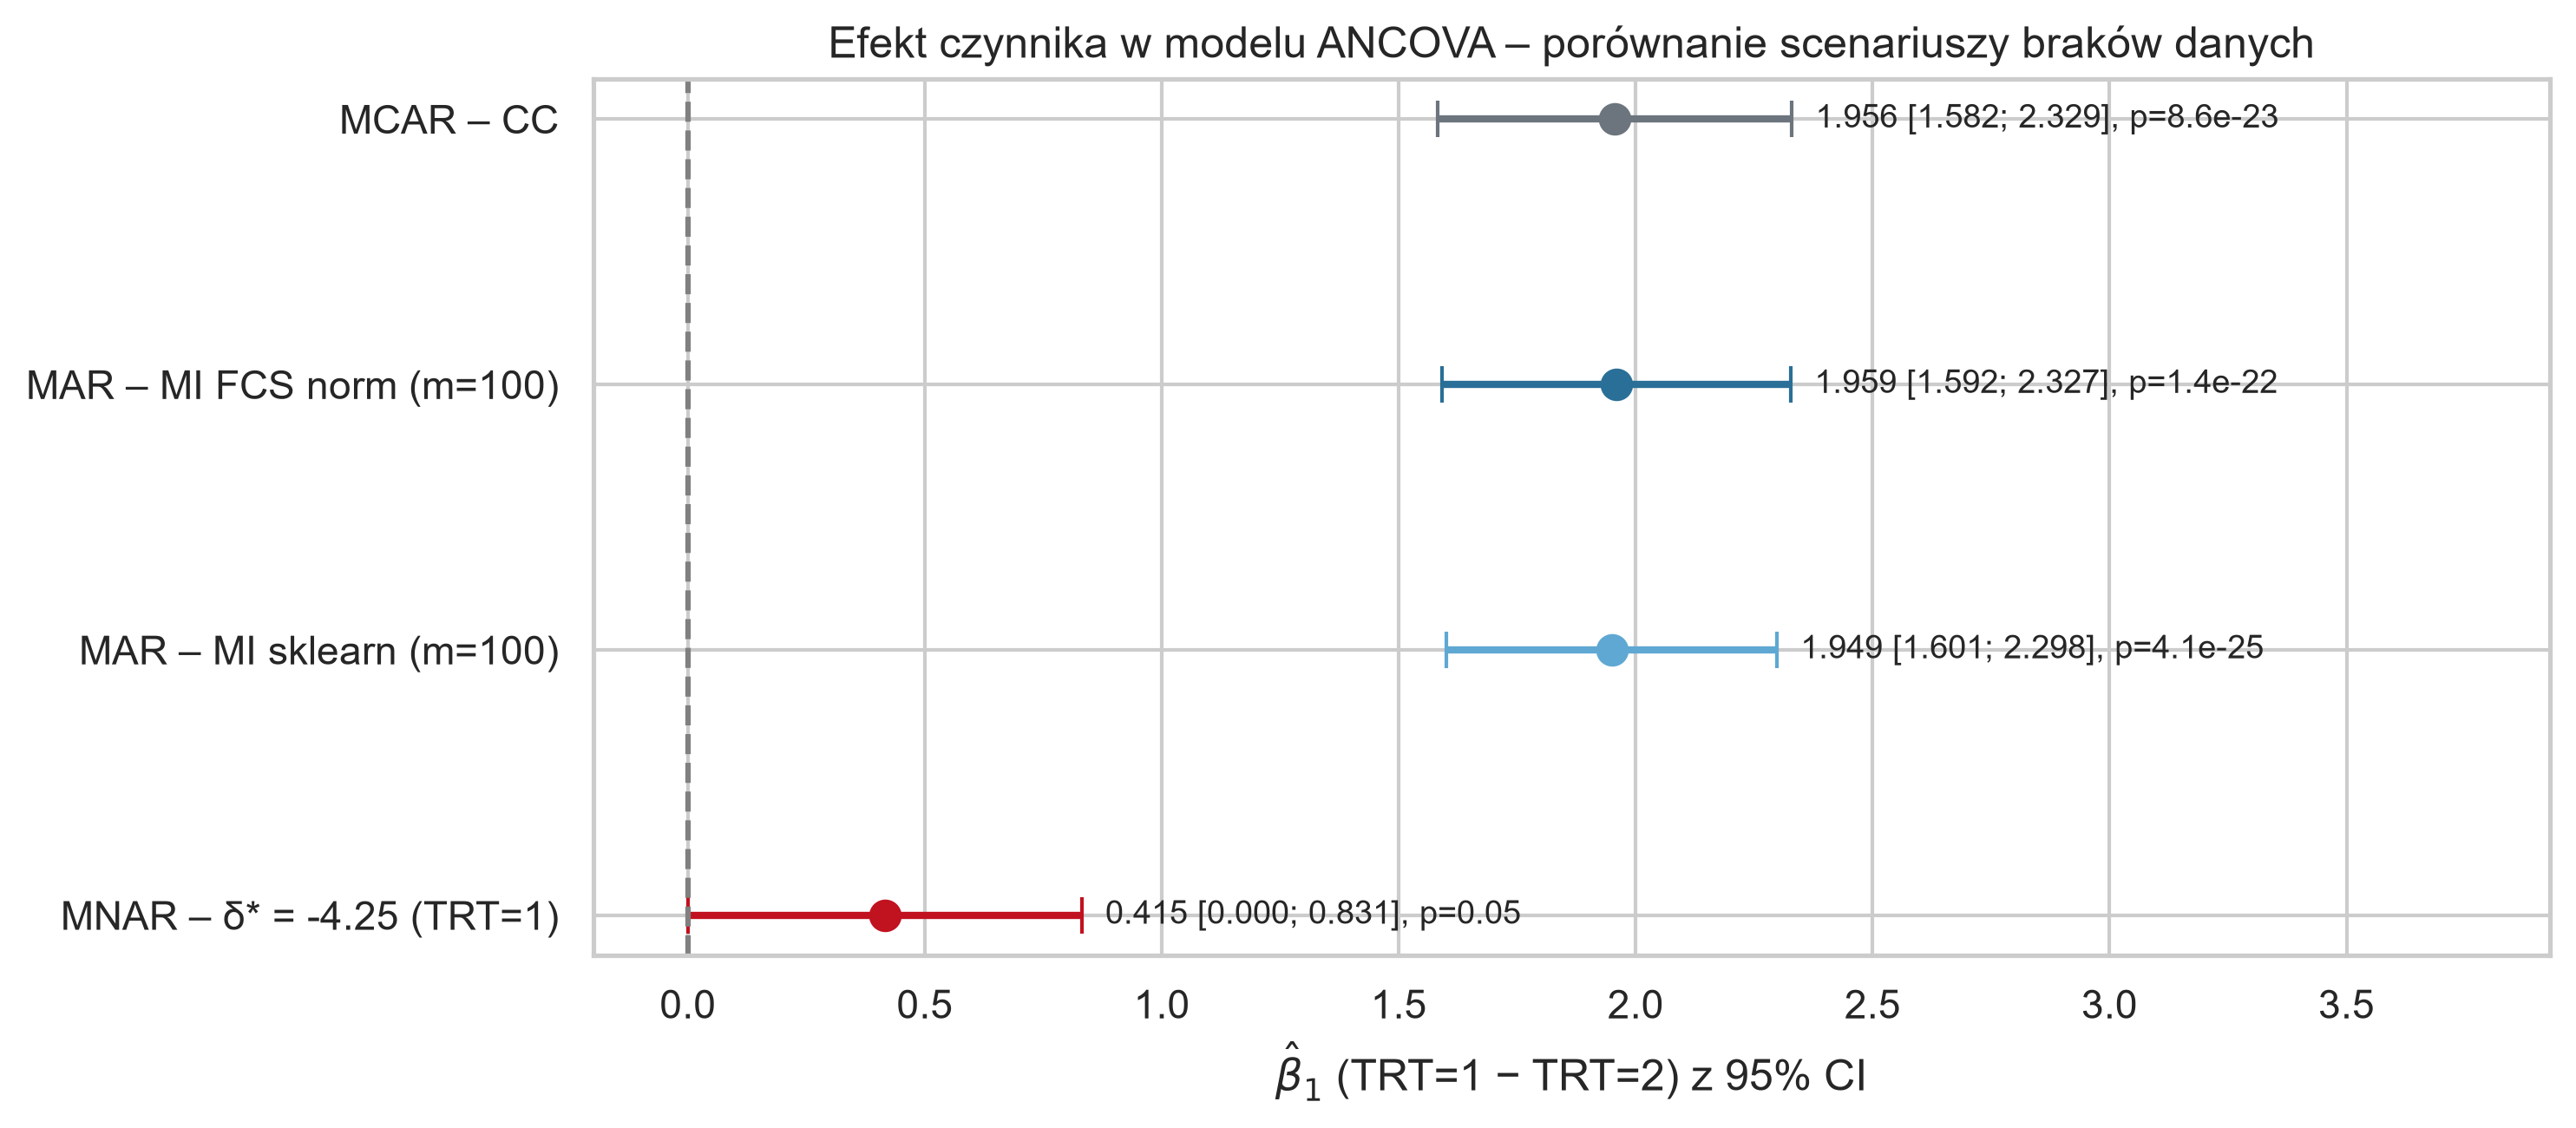

In [26]:
# PUNKT 4. Zestawienie istniejących wyników (bez ponownego uruchamiania imputacji).
from IPython.display import display, Image

# Gdy notebook został uruchomiony od początku, korzystamy z aktualnych obiektów
# z Punktu 3. Pozwala to uniknąć odczytania nieaktualnych plików CSV.
if all(nazwa in globals() for nazwa in ("comp", "mcar", "mar", "skala", "kryt_2d")):
    p4_por = comp.copy()
    p4_mcar = mcar["wsp"].copy()
    p4_mar = mar["wsp"].copy()
    p4_skala = skala.copy()
    p4_kryt2d = kryt_2d.copy()
else:
    # Wariant użyteczny przy otwieraniu tylko tej sekcji gotowego raportu.
    p4_por = pd.read_csv(RES / "tab_p3_porownanie.csv", index_col=0, encoding="utf-8-sig")
    p4_mcar = pd.read_csv(RES / "tab_p3_ancova_mcar.csv", index_col=0, encoding="utf-8-sig")
    p4_mar = pd.read_csv(RES / "tab_p3_ancova_mar.csv", index_col=0, encoding="utf-8-sig")
    p4_skala = pd.read_csv(RES / "tab_p3_skala_delta.csv", index_col=0, encoding="utf-8-sig")
    p4_kryt2d = pd.read_csv(RES / "tab_p3_tipping_2d_krytyczne.csv", encoding="utf-8-sig")
p4_zrodlo = pd.read_csv(CSV_FILE)

p4_podejscia = ["MCAR (CC)", "MAR (MI, FCS norm)"]
p4_tabela = pd.DataFrame({
    "MCAR (CC)": {
        "N": p4_por.loc["N", "MCAR (CC)"],
        "β0": p4_mcar.loc["β0 (wyraz wolny)", "Oszacowanie"],
        "β1 (TRT=1 vs 2)": p4_por.loc["β1", "MCAR (CC)"],
        "SE(β1)": p4_por.loc["SE(β1)", "MCAR (CC)"],
        "95% CI β1 — dolna": p4_por.loc["CI 2.5%", "MCAR (CC)"],
        "95% CI β1 — górna": p4_por.loc["CI 97.5%", "MCAR (CC)"],
        "p(β1)": p4_por.loc["p-value", "MCAR (CC)"],
        "β2 (Y_T1)": p4_por.loc["β2 (Y_T1)", "MCAR (CC)"],
        "p(β2)": p4_mcar.loc["β2 (Y_T1)", "p-value"],
        "R²": p4_por.loc["R²", "MCAR (CC)"],
        "FMI(β1)": np.nan,
    },
    "MAR (MI, FCS norm)": {
        "N": p4_por.loc["N", "MAR (MI, FCS norm)"],
        "β0": p4_mar.loc["β0 (wyraz wolny)", "Oszacowanie"],
        "β1 (TRT=1 vs 2)": p4_por.loc["β1", "MAR (MI, FCS norm)"],
        "SE(β1)": p4_por.loc["SE(β1)", "MAR (MI, FCS norm)"],
        "95% CI β1 — dolna": p4_por.loc["CI 2.5%", "MAR (MI, FCS norm)"],
        "95% CI β1 — górna": p4_por.loc["CI 97.5%", "MAR (MI, FCS norm)"],
        "p(β1)": p4_por.loc["p-value", "MAR (MI, FCS norm)"],
        "β2 (Y_T1)": p4_por.loc["β2 (Y_T1)", "MAR (MI, FCS norm)"],
        "p(β2)": p4_mar.loc["β2 (Y_T1)", "p-value"],
        "R²": p4_por.loc["R²", "MAR (MI, FCS norm)"],
        "FMI(β1)": p4_por.loc["FMI(β1)", "MAR (MI, FCS norm)"],
    },
})
p4_tabela.to_csv(RES / "tab_p4_podsumowanie.csv", encoding="utf-8-sig", index_label="Miara")

def p4_formatuj(wiersz, wartosc):
    if pd.isna(wartosc):
        return "—"
    if wiersz == "N":
        return f"{wartosc:.0f}"
    if wiersz.startswith("p("):
        return f"{wartosc:.2e}"
    if wiersz == "FMI(β1)":
        return f"{wartosc:.2%}"
    return f"{wartosc:.4f}"

p4_tabela_opis = p4_tabela.copy().astype(object)
for p4_wiersz in p4_tabela.index:
    for p4_kolumna in p4_tabela.columns:
        p4_tabela_opis.loc[p4_wiersz, p4_kolumna] = p4_formatuj(
            p4_wiersz, p4_tabela.loc[p4_wiersz, p4_kolumna]
        )

print("Tabela 4.1. Porównanie ocen modelu ANCOVA — CC i MI przy MAR:")
display(p4_tabela_opis)

p4_roz = p4_tabela.loc["β1 (TRT=1 vs 2)", "MAR (MI, FCS norm)"] - p4_tabela.loc["β1 (TRT=1 vs 2)", "MCAR (CC)"]
p4_redukcja_se = 100 * (1 - p4_tabela.loc["SE(β1)", "MAR (MI, FCS norm)"] / p4_tabela.loc["SE(β1)", "MCAR (CC)"])
p4_delta = float(p4_skala.loc["δ*", "wartość"])
p4_braki_trt1 = int(p4_zrodlo.loc[p4_zrodlo["trt"] == 1, "y_t2"].isna().sum())
print(f"Różnica ocen β1 (MI − CC): {p4_roz:+.4f}; zmiana SE(β1): −{p4_redukcja_se:.2f}%")
print(f"Weryfikacja alternatywną MI (sklearn): β1 = {p4_por.loc['β1', 'MAR (MI, sklearn)']:.4f}")
print(f"MNAR 1D: δ* = {p4_delta:.4f}, przesunięto {p4_braki_trt1} braków Y_T2 w TRT=1")
print(f"|δ*| / SD zaobserwowanych Y_T2 w TRT=1 = {abs(p4_skala.loc['δ* / SD(Y_T2 | TRT=1)', 'wartość']):.2f}")
print("Tabela 4.2. Punkty krytyczne δ1* w zależności od przesunięcia δ2 w grupie kontrolnej:")
display(p4_kryt2d.round(4))
print("Rysunek 4.1. Efekt TRT i 95% przedziały ufności w rozważanych podejściach:")
display(Image(filename=str(FIG / "fig9_forest_beta1.png")))

### Interpretacja wyników i wnioski

**Wpływ braków na wnioskowanie.** Brakuje 261 wartości $Y_{T2}$, tj. 32,42% próby; w `TRT=1` jest to 138/380 (36,32%), a w `TRT=2` — 123/425 (28,94%). W punkcie 2 model logistyczny wykazał związek występowania braków z zaobserwowanym $Y_{T1}$ ($p=0{,}0067$) oraz `TRT` ($p=0{,}0364$). Jest to **argument przeciw MCAR**, a więc przeciw bezwarunkowemu traktowaniu analizy pełnych przypadków jako nieobciążonej. Dane obserwowane **nie pozwalają odróżnić MAR od MNAR**; imputacja wielokrotna przy MAR stanowi założenie robocze, a nie empirycznie dowiedziony mechanizm.

**Oszacowanie efektu TRT.** W analizie pełnych przypadków ($N=544$) otrzymano $\hat\beta_1=1{,}9559$ (SE $=0{,}1901$, 95% CI $[1{,}5824;\,2{,}3293]$, $p=8{,}60\cdot10^{-23}$). W imputacji wielokrotnej FCS `norm` przy MAR ($N=805$, $m=100$) uzyskano $\hat\beta_1=1{,}9594$ (SE $=0{,}1871$, 95% CI $[1{,}5915;\,2{,}3273]$, $p=1{,}35\cdot10^{-22}$). W obu analizach odrzucamy $H_0:\beta_1=0$. Po skorygowaniu o $Y_{T1}$ przeciętna zmiana `CHG` jest więc **o około 1,96 jednostki większa w grupie `TRT=1`** niż w grupie kontrolnej. W modelu MAR skorygowane średnie wynoszą odpowiednio $+0{,}4483$ i $-1{,}5112$. Zbieżność ocen CC i MI (różnica około $0{,}0036$, czyli $0{,}18\%$) nie stanowi jednak testu poprawności założeń o brakach danych.

**Pozostały parametr modelu.** W modelu MAR uzyskano $\hat\beta_2=-0{,}3977$ (SE $=0{,}0960$, 95% CI $[-0{,}5866;\,-0{,}2088]$, $p=4{,}38\cdot10^{-5}$). Oznacza to, że przy ustalonej grupie `TRT` o jedną jednostkę większy poziom wyjściowy $Y_{T1}$ wiąże się przeciętnie z mniejszą zmianą `CHG` o około 0,40 jednostki. Jest to **zależność warunkowa w modelu**, nie dowód przyczynowego wpływu poziomu wyjściowego. Wyraz wolny $\hat\beta_0=2{,}8181$ odnosi się do `TRT=2` i $Y_{T1}=0$, dlatego ma ograniczoną interpretację praktyczną. Połączone $R^2$ dla MI wynosi około $0{,}1900$; należy traktować je opisowo, gdyż podejścia CC i MI operują na różnym zakresie informacji.

**Niepewność i korzyści z imputacji.** W MI błąd standardowy $\hat\beta_1$ jest mniejszy niż w CC o około $1{,}60\%$. Reguły Rubina uwzględniają jednak dodatkową niepewność między imputacjami: dla $\beta_1$ wariancja międzyimputacyjna wynosi $B=0{,}0107$, a frakcja brakującej informacji **FMI $=31{,}20\%$**. FMI opisuje brakującą informację o *konkretnym parametrze*, nie procent brakujących wierszy. Alternatywna MI z `sklearn` prowadzi do zbliżonej oceny $\hat\beta_1=1{,}9493$ i takiej samej decyzji weryfikacyjnej. Nieznaczne zmniejszenie SE nie oznacza, że imputacja usuwa problem braków ani że MAR jest prawdziwe.

**Analiza wrażliwości MNAR.** W wariancie 1D zmieniano wyłącznie 138 imputowanych wyników $Y_{T2}$ w grupie `TRT=1`. Pierwszy punkt krytyczny wynosi $\delta^*=-4{,}2481$ (około $-2{,}05$ odchylenia standardowego zaobserwowanego $Y_{T2}$ w tej grupie). Przy tym przesunięciu wynik osiąga granicę istotności $p\approx0{,}05$: dodatnia różnica między grupami przestaje być jednoznacznie istotna przy dalszym obniżaniu imputowanych wartości w rozpatrywanym otoczeniu punktu krytycznego. W analizie 2D próg zależy również od przesunięć w kontroli: dla $\delta_2=+2$ otrzymano $\delta_1^*\approx-2{,}7124$. Nie należy interpretować $\delta^*$ jako uniwersalnej granicy dla wszystkich mechanizmów MNAR; przy jeszcze silniejszych przesunięciach efekt może nawet zmienić znak. **Porównywanie wyników przy różnych założeniach i wyznaczanie punktów krytycznych pozwala ocenić wrażliwość wnioskowania na mechanizm powstawania braków danych.**

**Wniosek końcowy.** Model ANCOVA wskazuje na dodatnią, istotną statystycznie różnicę zmian `CHG` między grupami, praktycznie identyczną w CC oraz MI przy MAR. Ze względu na rozkład braków i zależność ich występowania od zaobserwowanych cech **MI przy MAR jest głównym wariantem wnioskowania**, a CC stanowi porównanie. Ostateczna interpretacja powinna uwzględniać analizę wrażliwości MNAR: decyzja o istotności czynnika `TRT` pozostaje stabilna w obu głównych estymacjach, lecz może się zmienić w określonych scenariuszach nieobserwowanych wyników.


---

# Punkt 5. [MIEJSCE NA ROZWIĄZANIE PUNKTU 5 ORAZ WNIOSKI KOŃCOWE – DO UZUPEŁNIENIA PRZEZ ZESPÓŁ]

> **[INSTRUKCJA DLA ZESPOŁU]**  
> W tym miejscu wstawcie pełne rozwiązanie **Punktu 5** oraz zbiorcze wnioski końcowe z całego projektu (Punkty 1–5).
> Po uzupełnieniu usuńcie tę ramkę informacyjną oraz dopiszcie swoje nazwiska na stronie tytułowej.

### Analiza (Punkt 5)
*[Miejsce na opis metody i realizację Punktu 5...]*

In [27]:
# TODO (ZESPÓŁ – PUNKT 5): Wklejcie poniżej kod dla Punktu 5
df_p5 = pd.read_csv(CSV_FILE)
print("[Punkt 5] Sekcja gotowa do uzupełnienia przez zespół. Liczba wierszy:", len(df_p5))

[Punkt 5] Sekcja gotowa do uzupełnienia przez zespół. Liczba wierszy: 805


### Podsumowanie końcowe całego zadania (Punkty 1–5)
*[Miejsce na syntetyczne wnioski końcowe zespołu...]*